# Explication du projet

L'entreprise place de marché est une société anglophone spécialisée dans la vente de produits en ligne. Elle met en relation des vendeurs proposant des articles à la vente et des acheteurs répartis dans différents pays.
Actuellement, la catégorisation des produits disponibles sur la plateforme est effectuée manuellement par les vendeurs. Ce processus, peut donc être sujet à des erreurs de saisie ou de subjectivité. Dans ce contexte, l’entreprise place de marché souhaite automatiser l’attribution des catégories produits afin d’optimiser ses processus et d’améliorer la qualité de la classification. Elle nous sollicite pour évaluer la faisabilité d’un système de classification automatique des produits, basé sur deux types de données fournies par les vendeurs:

- Les descriptions textuelles des produits en anglais
- Les images associées aux produits

Le présent notebook est consacré à l'étude de la faisabilité d'une classification automatique fondée sur les données textuelles des descriptions produits. Le second notebook portera sur l'étude de la faisabilité d'une classification automatique basée sur les images des produits. Enfin, le troisième notebook sera dédié à la mise en place d'une classification des produits en utiliant les images des produits. 

L'analyse se décomposera en plusieurs phase. Dans un premier temps le jeu de données contenant les descriptions des différents produits sera exploré afin de bien comprendre la nature et l'organisation des données qui nous intéressent. Les descriptions seront ensuite nettoyées et prétraitées. L'étape suivante consistera à extraire des caractéristique en vue d'une segmentation permettant de déterminer si les produits d'une même catégorie se regroupent bien ensemble. 

# Sommaire
- [1 Explication du projet](#Explication-du-projet)
- [2 Sommaire](#Sommaire)
- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Exploration de la table de données](#Exploration-de-la-table-de-données)
- [5 Choix des catégories](#Choix-des-catégories)
- [6 Nettoyage et prétraitement des données textuelles](#Nettoyage-et-prétraitement-des-données-textuelles)
- [7 Extraction de features](#Extraction-de-features)
- [8 Conclusions](#Conclusions)

# Import des bibliothèques et des données

**Bibliothèques**

In [1]:
# Affichage et interaction Jupyter
from IPython.display import display, HTML

# Système de fichiers et OS
import os
import time

# Manipulation et analyse de données
import pandas as pd
import numpy as np
import swifter
from collections import Counter

# Représentation graphiuqe
import seaborn as sns
import matplotlib.pyplot as plt
from plotnine import *
from wordcloud import WordCloud

# Nltk et traitement de texte
from nltk import download
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize, wordpunct_tokenize, RegexpTokenizer
from nltk.corpus import words, stopwords
from nltk.data import find

# Modèles et embeddings NLP - Gensim
import gensim.downloader as api
from gensim.utils import simple_preprocess
from gensim.models import Word2Vec, KeyedVectors

# Modèles et embeddings NLP - Transformers / Sentence-Transformers
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, TFAutoModel

# Machine Learning - Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Deep Learning - TensorFlow / Keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, GlobalAveragePooling1D
from tensorflow.keras.models import Model
from tensorflow import get_logger, stack
import tensorflow_hub as hub

**Resources NLTK**

In [2]:
# Téchargement de Wordnet si absent
try:
    find('corpora/wordnet')
except LookupError:
    download('wordnet')

# Téchargement des stopwords si absent
try:
    find('corpora/stopwords')
except LookupError:
    download('stopwords')

# Téchargement de Words si absent
try:
    find('corpora/words')
except LookupError:
    download('words')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\33647\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


**Données**

In [3]:
# import du jeu de données
Data_txt = pd.read_csv("../Data/flipkart_com-ecommerce_sample_1050.csv", index_col=0)

# Exploration de la table de données

La première étape consistera à explorer en détail la table de données afin d’identifier sa structure, les types de variables qu’elle contient, ainsi que la qualité des informations disponibles. Cette phase exploratoire permettra de mieux comprendre la nature des données, de repérer d’éventuelles valeurs manquantes ou anomalies, et d’anticiper les transformations nécessaires pour une exploitation optimale dans les étapes suivantes.

In [4]:
# Affichage des 5 premières lignes de la table de données
Data_txt.head(5)

,crawl_timestamp,product_url,product_name,product_category_tree,pid,retail_price,discounted_price,image,is_FK_Advantage_product,description,product_rating,overall_rating,brand,product_specifications
uniq_id,,,,,,,,,,,,,,
55b85ea15a1536d46b7190ad6fff8ce7,2016-04-30 03:22:56 +0000,http://www.flipkart.com/elegance-polyester-mul...,Elegance Polyester Multicolor Abstract Eyelet ...,"[""Home Furnishing >> Curtains & Accessories >>...",CRNEG7BKMFFYHQ8Z,1899.0,899.0,55b85ea15a1536d46b7190ad6fff8ce7.jpg,False,Key Features of Elegance Polyester Multicolor ...,No rating available,No rating available,Elegance,"{""product_specification""=>[{""key""=>""Brand"", ""v..."
7b72c92c2f6c40268628ec5f14c6d590,2016-04-30 03:22:56 +0000,http://www.flipkart.com/sathiyas-cotton-bath-t...,Sathiyas Cotton Bath Towel,"[""Baby Care >> Baby Bath & Skin >> Baby Bath T...",BTWEGFZHGBXPHZUH,600.0,449.0,7b72c92c2f6c40268628ec5f14c6d590.jpg,False,Specifications of Sathiyas Cotton Bath Towel (...,No rating available,No rating available,Sathiyas,"{""product_specification""=>[{""key""=>""Machine Wa..."
64d5d4a258243731dc7bbb1eef49ad74,2016-04-30 03:22:56 +0000,http://www.flipkart.com/eurospa-cotton-terry-f...,Eurospa Cotton Terry Face Towel Set,"[""Baby Care >> Baby Bath & Skin >> Baby Bath T...",BTWEG6SHXTDB2A2Y,NaN,NaN,64d5d4a258243731dc7bbb1eef49ad74.jpg,False,Key Features of Eurospa Cotton Terry Face Towe...,No rating available,No rating available,Eurospa,"{""product_specification""=>[{""key""=>""Material"",..."
d4684dcdc759dd9cdf41504698d737d8,2016-06-20 08:49:52 +0000,http://www.flipkart.com/santosh-royal-fashion-...,SANTOSH ROYAL FASHION Cotton Printed King size...,"[""Home Furnishing >> Bed Linen >> Bedsheets >>...",BDSEJT9UQWHDUBH4,2699.0,1299.0,d4684dcdc759dd9cdf41504698d737d8.jpg,False,Key Features of SANTOSH ROYAL FASHION Cotton P...,No rating available,No rating available,SANTOSH ROYAL FASHION,"{""product_specification""=>[{""key""=>""Brand"", ""v..."
6325b6870c54cd47be6ebfbffa620ec7,2016-06-20 08:49:52 +0000,http://www.flipkart.com/jaipur-print-cotton-fl...,Jaipur Print Cotton Floral King sized Double B...,"[""Home Furnishing >> Bed Linen >> Bedsheets >>...",BDSEJTHNGWVGWWQU,2599.0,698.0,6325b6870c54cd47be6ebfbffa620ec7.jpg,False,Key Features of Jaipur Print Cotton Floral Kin...,No rating available,No rating available,Jaipur Print,"{""product_specification""=>[{""key""=>""Machine Wa..."


In [5]:
# Affichage des informations liées au différentes variables
Data_txt.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1050 entries, 55b85ea15a1536d46b7190ad6fff8ce7 to f2f027ad6a6df617c9f125173da71e44
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   crawl_timestamp          1050 non-null   object 
 1   product_url              1050 non-null   object 
 2   product_name             1050 non-null   object 
 3   product_category_tree    1050 non-null   object 
 4   pid                      1050 non-null   object 
 5   retail_price             1049 non-null   float64
 6   discounted_price         1049 non-null   float64
 7   image                    1050 non-null   object 
 8   is_FK_Advantage_product  1050 non-null   bool   
 9   description              1050 non-null   object 
 10  product_rating           1050 non-null   object 
 11  overall_rating           1050 non-null   object 
 12  brand                    712 non-null    object 
 13  product_specifications  

La table de données contient 1 050 observations, chacune représentant un produit vendu sur la plateforme de flipkart. Ces produits sont décrits à l’aide de 14 variables. Parmi celles ci, 10 ne présentent aucune valeur manquante. Parmi les variables restantes, trois variables ne présentent qu’une seule valeur manquante chacune, ce qui reste négligeable, et une variable, en revanche, se distingue par un taux élevé de valeurs manquantes (plus de 300 valeurs absentes). Il s'agit de la variable indiquant la marque associée au produit qui ne sera pas utilisée pour la classification des produits. On repère la variable product_categorie_tree qui fournit des informations sur les catégories d’appartenance des produits, et pourra être utilisée comme variable cible et la variable description qui contient un texte descriptif du produit, qui représente une source d’informations pertinente pour le clustering ou la classification supervisée. 

Certaines descriptions seront affichées dans la suite du notebook. Pour cela il est important de connaitre les droits d'utilisation de ces données. Ceux ci peuvent être consultés sur le site de flipkart dans la section term of use. On peut y lire que l'ensemble du contenu de la plateforme est soummis à des droits de propriété intellectuelle et que par conséquent on peut utiliser ces données uniquement dans un cadre strictement personnel et non commercial.

In [6]:
# Calcul du nombre de valeurs uniques contenues dans chaque variable
Data_txt.nunique()

crawl_timestamp             149
product_url                1050
product_name               1050
product_category_tree       642
pid                        1050
retail_price                354
discounted_price            424
image                      1050
is_FK_Advantage_product       2
description                1050
product_rating               27
overall_rating               27
brand                       490
product_specifications      984
dtype: int64

L'analyse du nombre de valeurs unique par variable indique qu'il existe au total 642 catégorie différentes. Il faudra surement analyser de façon plus détaillée cette variable pour identifier les catégories les plus pertinentes à prendre en compte pour l'étude de faisabilité et pour la classification qui s'en suivra. Les noms de produits, l'url des produits ainsi que les description sont bien uniques ce qui indiquent qu'il n'y a pas de produits dupliqués dans la table de données. 

In [7]:
# Affichage du nombre de valeurs dupliquées par variable
for col in Data_txt.columns:
    n = Data_txt.duplicated(subset=col).sum()
    print(f'col: {col} -> duplicated : {n}')

col: crawl_timestamp -> duplicated : 901
col: product_url -> duplicated : 0
col: product_name -> duplicated : 0
col: product_category_tree -> duplicated : 408
col: pid -> duplicated : 0
col: retail_price -> duplicated : 695
col: discounted_price -> duplicated : 625
col: image -> duplicated : 0
col: is_FK_Advantage_product -> duplicated : 1048
col: description -> duplicated : 0
col: product_rating -> duplicated : 1023
col: overall_rating -> duplicated : 1023
col: brand -> duplicated : 559
col: product_specifications -> duplicated : 65


# Choix des catégories

Pour choisir les catégories à prendre en compte pour le projet on va analyser de facon plus détaillée les valeurs prises par la variable product_category_tree. 

In [8]:
# Affichage de 10 valeurs aléatoires de la variable product_category_tree
for i in Data_txt['product_category_tree'].sample(10):
    print(i)

["Watches >> Wrist Watches >> Sonata Wrist Watches"]
["Baby Care >> Diapering & Potty Training >> Changing Tables >> BASRA Changing Tables >> BASRA uepgrn Green Changing Table"]
["Baby Care >> Infant Wear >> Baby Boys' Clothes >> Polos & T-Shirts >> dongli Polos & T-Shirts >> dongli Striped Baby Boy's Polo Neck T-Shirt (Pac..."]
["Beauty and Personal Care >> Fragrances >> Deodorants >> Combos >> Park Avenue Combos"]
["Kitchen & Dining >> Cookware >> Pots & Pans >> Woks & Kadhais >> Kosher Woks & Kadhais"]
["Baby Care >> Infant Wear >> Baby Boys' Clothes >> Polos & T-Shirts >> Dongli Polos & T-Shirts >> Dongli Striped Baby Boy's Polo Neck T-Shirt"]
["Home Decor & Festive Needs >> Showpieces >> Ethnic >> Tatvaarts Ethnic"]
["Home Furnishing >> Bath Linen >> Towels"]
["Watches >> Wrist Watches >> Sonata Wrist Watches"]
["Kitchen & Dining >> Coffee Mugs >> Prithish Coffee Mugs"]


La variable product_category_tree contient des informations hiérarchiques sur les catégories des produits, organisées selon différents niveaux de granularité. Ces niveaux sont séparés par le délimiteur >>, allant de la catégorie la plus générale à la plus spécifique. Afin de déterminer les catégories les plus pertinentes à retenir, on peut analyser la profondeur des arborescences présents dans la variable. Ensuite, on peut s'intéresser aux effectifs associés à chaque niveau, ce qui permettra d’identifier les niveaux de catégorie présentant un effectif suffisant pour être exploitables ainsi que les déséquilibres éventuels entre les branches.

In [9]:
# Affichage du nombre de produits associés à une profondeur de l'arborescence des catégories donnée
Data_txt['product_category_tree'].str.count('>>').value_counts()

product_category_tree
2    368
4    278
3    274
5     70
6     57
1      3
Name: count, dtype: int64

La majorités des produits sont associés à 3 niveau de catégories. Le fait que plus de la moitié des produits (645) n'aient pas plus de 4 niveaux de catégories indique qu'il serait préférable d'utiliser au maximum ce niveau de maniere à ce que la plupart des produits soit caractérisé par le même niveau. Avant de s'arréter définitivement sur un choix on va regarder les effectifs associés au quatre premiers niveaux de catégories à l'aide de représentations graphiques.

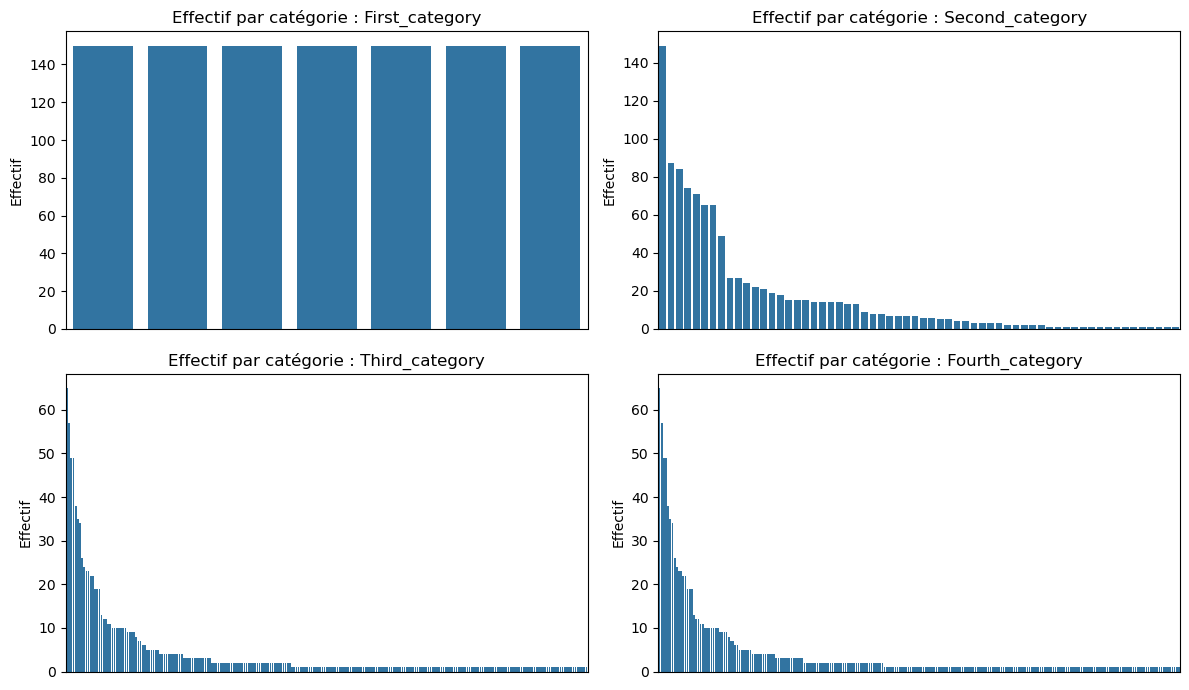

In [10]:
# Suppression des caractéries [, ", et ]
Data_txt['product_category_tree'] = Data_txt['product_category_tree'].str.replace(r'[\[\]\"]', '', regex=True)

# Extraction des catégories
Data_txt['First_category'] = Data_txt['product_category_tree'].str.split('>>').str[0].str.strip()
Data_txt['Second_category'] = Data_txt['product_category_tree'].str.split('>>').str[1].str.strip()
Data_txt['Third_category'] = Data_txt['product_category_tree'].str.split('>>').str[2].str.strip()
Data_txt['Fourth_category'] = Data_txt['product_category_tree'].str.split('>>').str[2].str.strip()

# Listes des catégories
list_cat = ['First_category', 'Second_category', 'Third_category', 'Fourth_category']

# Initialisation de la figure
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# Applatissement de l'objet axe
axes_flat = axes.flatten()

# Pour chaque niveau de catégorie
for i, col in enumerate(list_cat):
    
    # Calcul du nombre de modalités uniques
    nb_modalites = Data_txt[col].nunique()

    # Tri des catégories de la plus fréquente à la moins fréquente
    order = Data_txt[col].value_counts().index

    # Construction du graphique
    sns.countplot(
        data=Data_txt,
        x=col,
        ax=axes_flat[i], 
        order=order
    )

    # Ajout des labels
    axes_flat[i].set_title(f"Effectif par catégorie : {col}")
    axes_flat[i].set_ylabel("Effectif")
    axes_flat[i].set_xlabel("")

    # Suppression des labels et graduations de l'axe des abscisse des graphiques
    axes_flat[i].set_xticklabels([])
    axes_flat[i].tick_params(axis='x', length=0)

# Ajustement du graphique
plt.tight_layout()

# Affichage du graphique
plt.show()

Lorsque l’on conserve le deuxième, troisième ou quatrième niveau de la hiérarchie des catégories, on observe un grand nombre de modalités, souvent très déséquilibrées en termes de taille respective. On remarque en effet, que certaines catégories contiennent un nombre important de produits tandis que d’autres sont très peu représentées, ce qui peut compliquer la classification.

En revanche, en se focalisant uniquement sur le premier niveau de catégorie, c'est à dire la catégorie la plus générale, on obtient un ensemble de 7 catégories, dont les tailles sont parfaitement équilibrées. Cette distribution plus homogène apparait plus pertinente pour la modélisation et garantit une meilleure représentativité des classes. Ainsi les catégories attribuées à chaque produit correspondront au premier niveau de la hiérarchie. 

In [11]:
# Encodage des catégories pour obtenir des labels numériques
Encoder = LabelEncoder()
Data_txt["label"] = Encoder.fit_transform(Data_txt["First_category"])

Avant de se lancer dans une analyse plus fine basée sur des méthodes de traitement automatique du langage naturel (NLP), il est important de vérifier si la longueur des descriptions diffère significativement selon les catégories de produits. En effet, si chaque catégorie se distingue clairement par une taille spécifique de description, il pourrait être possible de classifier efficacement les produits simplement à partir de cette caractéristique quantitative, sans recourir à des techniques NLP plus complexes. Cette étape préliminaire permet donc de déterminer si la longueur des descriptions constitue un critère discriminant suffisant, ce qui pourrait simplifier considérablement la tâche de classification.

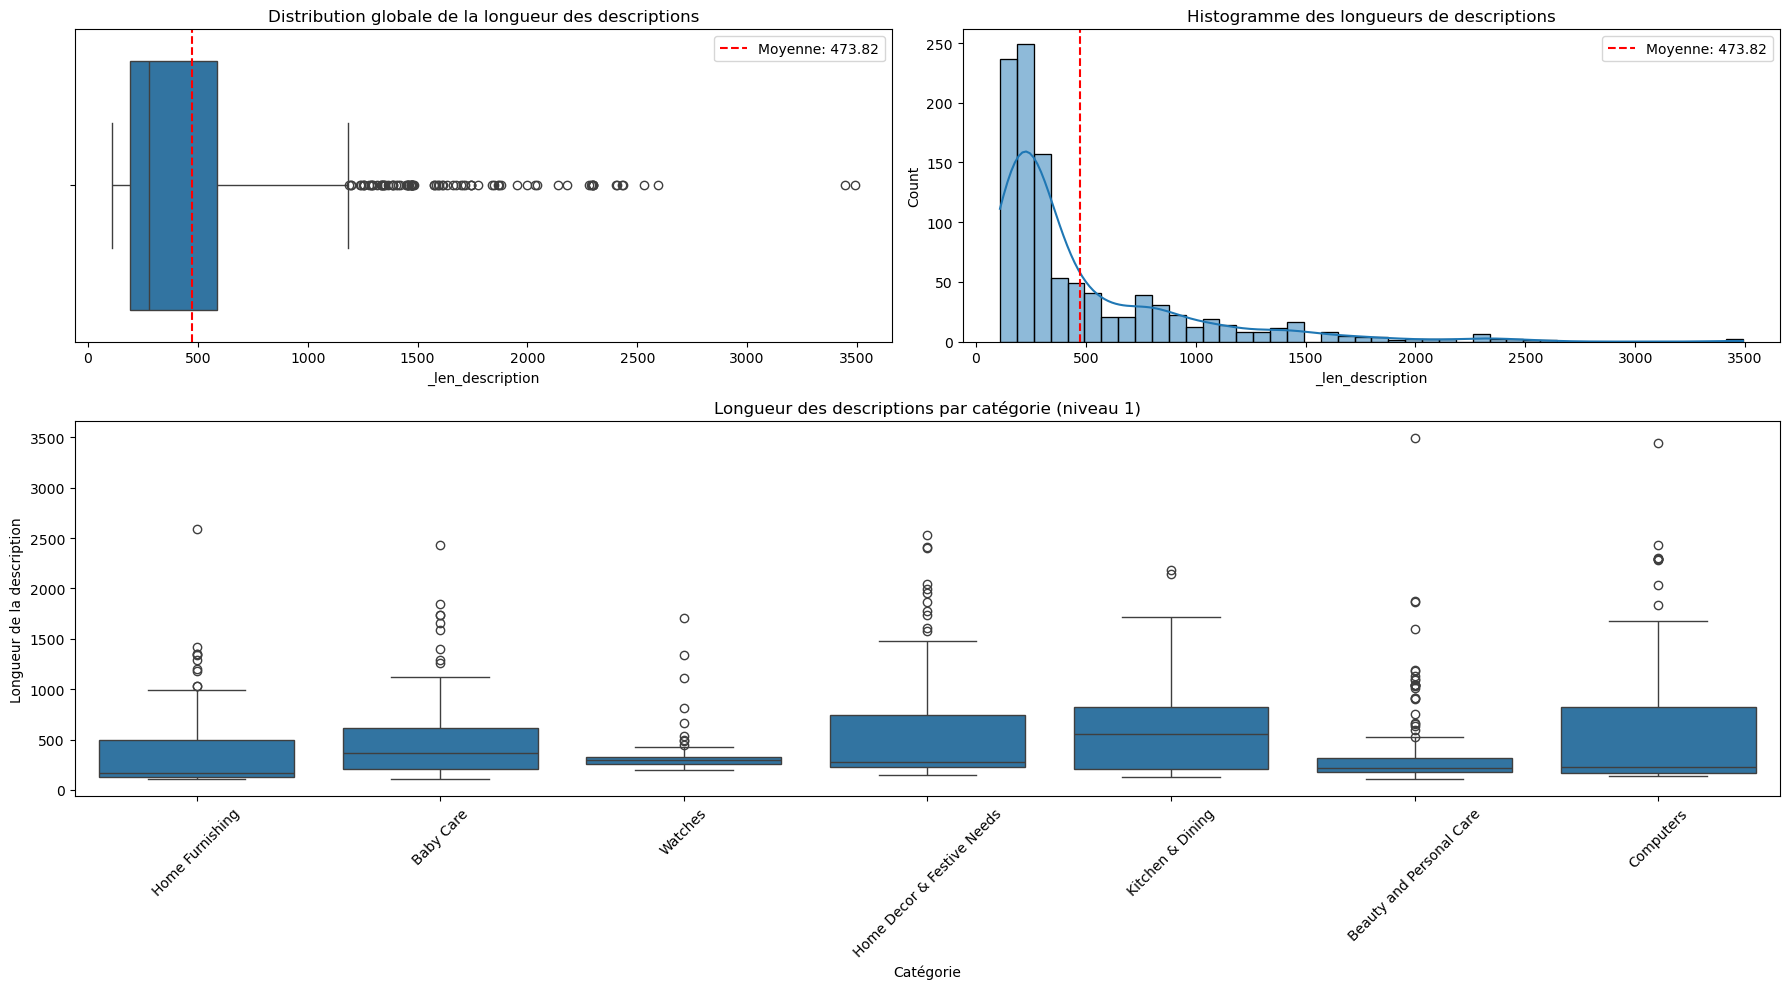

In [12]:
# Création d'une variable représentant la longueur des descriptions
Data_txt['_len_description'] = Data_txt['description'].str.len()

# Calcul de la taille moyenne des descriptions
mean_len = Data_txt['_len_description'].mean()

# Initialisation de la figure 
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# 1er graphique : boxplot global
ax1 = fig.add_subplot(gs[0, 0])
sns.boxplot(x=Data_txt['_len_description'], ax=ax1)
ax1.axvline(mean_len, color='red', linestyle='--', label=f'Moyenne: {mean_len:.2f}')
ax1.set_title("Distribution globale de la longueur des descriptions")
ax1.legend()

# 2e graphique : histogramme avec KDE
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(Data_txt['_len_description'], kde=True, ax=ax2)
ax2.axvline(mean_len, color='red', linestyle='--', label=f'Moyenne: {mean_len:.2f}')
ax2.set_title("Histogramme des longueurs de descriptions")
ax2.legend()

# 3e graphique : boxplot vertical par groupe de catégories
ax3 = fig.add_subplot(gs[1, :])
sns.boxplot(x=Data_txt['First_category'], y=Data_txt['_len_description'], ax=ax3)
ax3.set_title("Longueur des descriptions par catégorie (niveau 1)")
ax3.set_xlabel("Catégorie")
ax3.set_ylabel("Longueur de la description")
ax3.tick_params(axis='x', rotation=45)

# Ajustement du graphique
plt.tight_layout()

# Affichage du graphique
plt.show()

In [13]:
# Description statistique de la variable _len_description
Data_txt['_len_description'].describe()

count    1050.000000
mean      473.820952
std       457.910422
min       109.000000
25%       192.000000
50%       278.000000
75%       588.250000
max      3490.000000
Name: _len_description, dtype: float64

Les descriptions ont une taille moyenne de 474 ± 458 caractères, avec des longueurs variant de 109 à 3490 caractères. La majorité des descriptions sont plus courtes que la moyenne, cette dernière étant tirée vers le haut par quelques descriptions particulièrement longues. On remarque également, après analyses des boxplots, que la taille des descriptions ne semble pas dépendre de la catégorie des produits.

In [14]:
# Sauvegarde de la table de données
Data_txt.to_csv("../Output/Table/Data.csv", index=True)

# Nettoyage et prétraitement des données textuelles

L'étude de faisabilité de la classification des produits à partir des données textuelle se fera donc grâce à une approche de traitement automatique du langage naturelle qui se décomposera en plusieurs étapes successives allant du nettoyage des données à l’analyse des groupes formés par clustering. Les groupes obtenus par clustering seront comparés aux catégories réelles, afin d’évaluer dans quelle mesure les descriptions permettent de retrouver la catégorie réelle d'un produit.

Dans un premier temps, les descriptions textuelles des produits seront nettoyées et prétraitées pour les rendres plus exploitables. Pour cela, une fonction de traitement, nommée process_text, sera utilisée pour enchaîner de manière paramétrable toutes les étapes classiques du prétraitement en NLP.
- 1) tous les caractères seront convertis en minuscules pour uniformiser les textes et éviter les doublons liés à la casse
- 2) les descriptions seront découpées en tokens à l’aide d’un tokeniseur basé sur des expressions régulières, ce qui permet de séparer efficacement les mots tout en excluant la ponctuation.
- 3) les mots très fréquents sans valeur sémantique forte (comme the, and, is, etc) sont retirés. Ces mots seront listés dans stop_words
- 4)  les mots ayant une longueur inférieure à un seuil minimum (par défaut 3 caractères) seront éliminés, car ils sont souvent également peu porteurs de sens
- 5)  seuls les mots strictement alphabétiques seront conservés, en excluant les chaînes contenant des chiffres ou des symboles si force_is_alpha est activé.
- 6) Les mots seront soit réduits à leur racine canonique (lemmatisation), soit à leur forme racinaire (stemming), selon le paramètre lemm_or_stemm. Ces opérations visent à regrouper les variantes d’un même mot.
- 7) une liste de mots rares pourra être fournie pour exclure les mots peu informatifs ou apportant du bruit.
- 8) Si une liste de mots anglais est fournie, seuls les mots présents dans ce lexique sont conservés.
- 9) Une liste personnalisée de mots à exclure pourra également être spécifiée pour retirer certains mots jugés non pertinents.

Les deux premières étapes seront exécutées automatiquement, tandis que les suivantes seront contrôlées par des paramètres définis en entrée de la fonction.

Une seconde fonction sera mise en place afin de suivre et visualiser l’impact de chaque étape de nettoyage sur les descriptions. Celle ci permettra d’afficher, après chaque transformation appliquée, le nombre total de tokens restants ainsi que le nombre de tokens uniques. On pourra alors évaluer l’effet de chaque étape en regardant par exemple, combien de mots sont supprimés lors du filtrage des stopwords ou du nettoyage des mots courts.

## Fonction de prétraitement et d'analyse des résultats

In [15]:
def process_text(doc, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=3,
                   force_is_alpha=False,
                   eng_words=None,
                   common_words=None):
    
    """
    Applique un prétraitement sur un document textuel en appliquant différentes opérations de nettoyage et de transformation.

    Paramètres
        doc (str): Texte brut à traiter.
        stop_words (list): Liste de mots à exclure. Si vide ou None, aucun mot n'est supprimé à cette étape.
        rejoin (bool): Si True, retourne une chaîne de caractères nettoyée
                       Si False, retourne une liste de tokens nettoyés.
        list_of_rare_words (list): Liste de mots rares à supprimer.
        lemm_or_stemm (str): Méthode de transformation des tokens ('lem' pour lematisation ou 'stemm' pour stemming)
        min_len_words (int): Longueur minimale des mots à conserver. Les mots plus courts sont supprimés.
        force_is_alpha (bool): Si True, supprime tous les tokens contenant des caractères non alphabétiques.
        eng_words (list): Liste de mots anglais valides. Si fournie, seuls les mots présents dans cette liste seront conservés.
        common_words (list): Liste de mots à exclure car considérés comme trop fréquents ou peu discriminants entre catégories.

   Sortie
        list of str or str : Liste de tokens nettoyés ou texte nettoyé selon la valeur de `rejoin`.
    """
    
    # Si aucune liste de stopwords est fournie, création d'une liste vide
    if not stop_words:
        stop_words=[]
        
    # Si aucune liste de mots rares est fournie, création d'une liste vide
    if not list_of_rare_words:
        list_of_rare_words=[]
        
    # Si aucune liste de mots anlais est fournie, création d'une liste vide
    if not eng_words:
        eng_words=[]
     
    # Si aucune liste de mots communs est fournie, création d'une liste vide
    if not common_words:
        common_words=[]
        
    # Conversion des caractères en minuscules
    doc = doc.lower().strip()
    
    # tokenization des description
    tokenizer = RegexpTokenizer(r"\w+")
    raw_tokens_list = tokenizer.tokenize(doc)
    
    # Supression des stopwords et des mots rares
    cleaned_tokens_list =  [w for w in raw_tokens_list if w not in stop_words]
    non_rare_tokens = [w for w in cleaned_tokens_list if w not in list_of_rare_words]
    
    # Si une longueur minimum est fourni, suppression des token de longueur inférieure
    if min_len_words: 
        more_than_N = [w for w in non_rare_tokens if len(w)>=min_len_words]
    else: 
        more_than_N = non_rare_tokens
    
    # Si force_is_alpha is True, on conserve que les caractères alphabétiques
    if force_is_alpha :
        alpha_tokens = [w for w in more_than_N if w.isalpha()]
    else :
        alpha_tokens = more_than_N
        
    # Choix de la méthode de traitement des mots  
    if lemm_or_stemm =='lem':
        trans = WordNetLemmatizer()
        trans_text = [trans.lemmatize(i) for i in alpha_tokens]
    elif lemm_or_stemm == 'stemm' : 
        trans = PorterStemmer()
        trans_text = [trans.stem(i) for i in alpha_tokens]
    else:
        trans_text = alpha_tokens

    # Supression des mots non anglais
    if eng_words:
        engl_text = [i for i in trans_text if i in eng_words]
    else:
        engl_text = trans_text
        
    # Suppression des mots communs à plusieurs catégories
    final = [w for w in engl_text if w not in common_words]
    
    # Si infique, jointure des tokens
    if rejoin:
        return ' '.join(final)
    
    return final

In [16]:
def display_token_info(tokens, display_all_token = False):
    """
    Affiche des informations sur une liste de tokens.

    Paramètres
        tokens (list of str): Liste de tokens à analyser.
        display_all_token (bool): Affiche ou non tous les tokens sous forme de chaîne de caractères, 
        séparés par des espaces.
    """
    
    # Si display all token est True, affichage de la totalité des tokens
    if display_all_token:
        print(" ".join(tokens))
        print(" ")
        
    # Affichage du nombre total de token et du nombre de tokens uniques
    print(f'nb tokens {len(tokens)}, nb tokens uniques {len(set(tokens))}')
    
    # Affichage des 30 premiers tokens
    print(tokens[:30])

##  Prétraitement

Les premières étapes qui vont être étudiées dans cette partie correspondent à la conversion des descriptions en minuscules, à la suppression des stopwords et à la suppression des tokens non alphabétiques. Pour cela, on va selectionner une description de produit et comparer sa version brute à sa version prétraitée.

In [17]:
# Extraction de la description d'un produit
desc_one_product = Data_txt['description'].sample(1, random_state=8).iloc[0]

# Affichage de la description d'un produit
desc_one_product

"Key Features of RoQ Slim Multimedia 105key Flexible Wired USB Flexible Keyboard Size: Handheld,RoQ Slim Multimedia 105key Flexible Wired USB Flexible Keyboard (White) Price: Rs. 399 Working Environment. It Fits Easily In Your Briefcase Or Backpack. The Keyboard Can Be Cleaned With Water, Alcohol Or Disinfectant To Help Prevent The Spread Of The Disease And Germs. It Is Suitable For Public Place Use Such As School, Restaurant, Or Hospital Where Clean Keyboard Is A Requirement. This Sealed Keyboard Can Be Easily Cleaned, Also Good For Use In Dusty Area Such As Factory, Or Outdoor. Quiet Keystroke Is A Good Match For Library Use. If You Are Not Used To This Keyboard, You May Push These Keys A Tiny Bit Harder To Get Output. Dustproof Washable Usb Plug Weight: 0.45lbs (200g) Operation Temperature Is -20c- +60c. Storage Temperature Is -30c - +70c,Specifications of RoQ Slim Multimedia 105key Flexible Wired USB Flexible Keyboard (White) General Specifications Interface Wired USB Brand RoQ Mod

In [18]:
# Conversion des descriptions en minuscule + tokenisation
tokens = process_text(desc_one_product, stop_words=None, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=None,
                   force_is_alpha=False,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens, display_all_token=True)

key features of roq slim multimedia 105key flexible wired usb flexible keyboard size handheld roq slim multimedia 105key flexible wired usb flexible keyboard white price rs 399 working environment it fits easily in your briefcase or backpack the keyboard can be cleaned with water alcohol or disinfectant to help prevent the spread of the disease and germs it is suitable for public place use such as school restaurant or hospital where clean keyboard is a requirement this sealed keyboard can be easily cleaned also good for use in dusty area such as factory or outdoor quiet keystroke is a good match for library use if you are not used to this keyboard you may push these keys a tiny bit harder to get output dustproof washable usb plug weight 0 45lbs 200g operation temperature is 20c 60c storage temperature is 30c 70c specifications of roq slim multimedia 105key flexible wired usb flexible keyboard white general specifications interface wired usb brand roq model slim multimedia 105key flexib

Après la tokenisation du texte et la conversion de l'ensemble des caractères en minuscules, on observe que la description analysée contient 205 tokens au total, parmi lesquels 119 sont uniques. On note également la présence fréquente de mots dits vides de sens (ou stopwords), comme in, it, ou of, qui sont des mots à faible valeur sémantique et qui apparaitront probablement de façon fréquente dans toutes les descriptions, sans apporter d’information discriminante. Ces stopwords seront donc retirés des descriptions dans l'étape suivante.

In [19]:
# Définition des stop_words
stop_words = set(stopwords.words('english'))

# Ajout de l'étape de suppression des stop_words
tokens = process_text(desc_one_product, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=None,
                   force_is_alpha=False,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens, display_all_token=True)

key features roq slim multimedia 105key flexible wired usb flexible keyboard size handheld roq slim multimedia 105key flexible wired usb flexible keyboard white price rs 399 working environment fits easily briefcase backpack keyboard cleaned water alcohol disinfectant help prevent spread disease germs suitable public place use school restaurant hospital clean keyboard requirement sealed keyboard easily cleaned also good use dusty area factory outdoor quiet keystroke good match library use used keyboard may push keys tiny bit harder get output dustproof washable usb plug weight 0 45lbs 200g operation temperature 20c 60c storage temperature 30c 70c specifications roq slim multimedia 105key flexible wired usb flexible keyboard white general specifications interface wired usb brand roq model slim multimedia 105key flexible sales package 1 keyboard type flexible keyboard model name slim multimedia flexible keyboard color white size handheld warranty covered warranty manufacturing damage war

La suppression des stopwords entraîne une forte réduction du nombre total de tokens, qui passe de 205 à 153, soit une diminution de près de 25 %. Cette forte réduction est obtenue en ne retirant que 24 tokens uniques, ce qui confirme que ces mots vides apparaissaient de manière répétée dans la description. Ici on va également éliminer les termes non alphabétiques  car il s'agira souvent de dimensions, ou de prix qui ne permettront pas de différencer un produit d'une catégorie à une autre.

In [20]:
# Ajout de l'étape de suppression des tokens non alphabétiques
tokens = process_text(desc_one_product, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=None,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens, display_all_token=True)

key features roq slim multimedia flexible wired usb flexible keyboard size handheld roq slim multimedia flexible wired usb flexible keyboard white price rs working environment fits easily briefcase backpack keyboard cleaned water alcohol disinfectant help prevent spread disease germs suitable public place use school restaurant hospital clean keyboard requirement sealed keyboard easily cleaned also good use dusty area factory outdoor quiet keystroke good match library use used keyboard may push keys tiny bit harder get output dustproof washable usb plug weight operation temperature storage temperature specifications roq slim multimedia flexible wired usb flexible keyboard white general specifications interface wired usb brand roq model slim multimedia flexible sales package keyboard type flexible keyboard model name slim multimedia flexible keyboard color white size handheld warranty covered warranty manufacturing damage warranty summary day replacement warranty service type replacement

L’étape de suppression des tokens non alphabétiques a permis d’éliminer 14 éléments supplémentaires, principalement composés de valeurs numériques. Il peut également être pertinent, à ce stade du prétraitement, d’introduire un filtrage basé sur la longueur des mots. En effet, les mots très courts (souvent de moins de 3 caractères) ne sont pas toujours informatifs et peuvent être retirés sans perte significative d'information.

In [21]:
# Ajout de l'étape de suppression des mots courts
tokens = process_text(desc_one_product, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens, display_all_token=True)

key features roq slim multimedia flexible wired usb flexible keyboard size handheld roq slim multimedia flexible wired usb flexible keyboard white price working environment fits easily briefcase backpack keyboard cleaned water alcohol disinfectant help prevent spread disease germs suitable public place use school restaurant hospital clean keyboard requirement sealed keyboard easily cleaned also good use dusty area factory outdoor quiet keystroke good match library use used keyboard may push keys tiny bit harder get output dustproof washable usb plug weight operation temperature storage temperature specifications roq slim multimedia flexible wired usb flexible keyboard white general specifications interface wired usb brand roq model slim multimedia flexible sales package keyboard type flexible keyboard model name slim multimedia flexible keyboard color white size handheld warranty covered warranty manufacturing damage warranty summary day replacement warranty service type replacement co

Cette dernière étape de nettoyage n'a permis de retirer qu'un token Rs qui correspondrait à l’abréviation de la monnaie utilisée pour la transaction. 

### Transformations des tokens : Lementisation / Stementisation

Une autre étape de traitement de données textuelles vise à regrouper les différentes variantes d'un mot. Deux approches sont possibles: 

- Le stemming est une méthode simple et rapide qui permet de supprimer les suffixes ou préfixes des tokens pour ramener les mots à leur forme racinaire. Le produit de cette transformation n'est donc pas un vrai mot. 
- La lemmatisation est une approche plus complexe. Elle utilise un dictionnaire pour transformer un mot dans sa forme canonique en tenant compte de son contexte grammatical. Cette approche est plus précise et grammaticalement plus correcte. Le produit de cette transformation correspond à des mots qui existent réellement.

In [22]:
# Ajout de l'étape de stemmentization
tokens = process_text(desc_one_product, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm='stemm',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens,  display_all_token=True)


key featur roq slim multimedia flexibl wire usb flexibl keyboard size handheld roq slim multimedia flexibl wire usb flexibl keyboard white price work environ fit easili briefcas backpack keyboard clean water alcohol disinfect help prevent spread diseas germ suitabl public place use school restaur hospit clean keyboard requir seal keyboard easili clean also good use dusti area factori outdoor quiet keystrok good match librari use use keyboard may push key tini bit harder get output dustproof washabl usb plug weight oper temperatur storag temperatur specif roq slim multimedia flexibl wire usb flexibl keyboard white gener specif interfac wire usb brand roq model slim multimedia flexibl sale packag keyboard type flexibl keyboard model name slim multimedia flexibl keyboard color white size handheld warranti cover warranti manufactur damag warranti summari day replac warranti servic type replac cover warranti physic damag
 
nb tokens 138, nb tokens uniques 80
['key', 'featur', 'roq', 'slim',

Ici, on observe que l’étape de stemming a permis de tronquer certains mots pour les ramener à leur forme racinaire. Cela a entraîné une légère réduction du nombre de tokens uniques, passant de 83 à 80. En particulier, les termes "cleaned" et "clean" ont tous deux été ramenés à la racine "clean". De même, "used" et "use" ont été unifiés sous la forme "use".
Cette étape de transformation permet de réduire la redondance lexicale de la description en regroupant les variantes d’un même mot.

In [23]:
# Ajout de l'étape de lemmentisation
tokens = process_text(desc_one_product, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm='lem',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens,  display_all_token=True)

key feature roq slim multimedia flexible wired usb flexible keyboard size handheld roq slim multimedia flexible wired usb flexible keyboard white price working environment fit easily briefcase backpack keyboard cleaned water alcohol disinfectant help prevent spread disease germ suitable public place use school restaurant hospital clean keyboard requirement sealed keyboard easily cleaned also good use dusty area factory outdoor quiet keystroke good match library use used keyboard may push key tiny bit harder get output dustproof washable usb plug weight operation temperature storage temperature specification roq slim multimedia flexible wired usb flexible keyboard white general specification interface wired usb brand roq model slim multimedia flexible sale package keyboard type flexible keyboard model name slim multimedia flexible keyboard color white size handheld warranty covered warranty manufacturing damage warranty summary day replacement warranty service type replacement covered w

## Analyse de la fréquence des mots dans le corpus

Dans cette partie on va analyser la fréquence des mots sur l'ensemble du corpus, c'est à dire sur l'ensemble des description de produits. Pour cela, on va construire le corpus à partir de chacune des descriptions, puis on appliquera les étapes étudiées dans la partie précédente à savoir la conversion du texte en minuscule, la tokenisation, la suppression des tokens non alphabétique et la supression des stopwords. 

In [24]:
# Construction du corpus complet
raw_corpus = " ".join(Data_txt['description'].values)

# Conversion en minuscule du corpus + tokenization + supression des stop_words 
tokens_corpus = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=None,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens_corpus)

nb tokens 55622, nb tokens uniques 4897
['key', 'features', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'cm', 'height', 'pack', 'price', 'rs', 'curtain', 'enhances', 'look', 'interiors', 'curtain', 'made', 'high']


L’ensemble du corpus, constitué des descriptions de chacun des produits après prétraitement, contient un total de 55622 tokens, parmi lesquels 4897 sont uniques. Afin de mieux comprendre la structure lexicale du corpus, on peut maintenant examiner la fréquence d’apparition de chaque mot. Cela permettra d'identifier les mots rares c’est à dire ceux qui n’apparaissent qu’une ou deux fois dans l’ensemble du corpus. Ces mots sont peu susceptibles d’apporter une information discriminante pour la classification des produits, et pourront donc être exclus du vocabulaire final.

In [25]:
# Compte du nombre d'occurence de chaque token dans le corpus
occ = pd.Series(tokens_corpus).value_counts()

# Affichage de tmp
occ

rs          911
products    631
free        618
buy         581
delivery    567
           ... 
playing       1
husband       1
merry         1
stroll        1
png           1
Name: count, Length: 4897, dtype: int64

On observe que certains mots sont très fréquents dans le corpus : les plus représentés apparaissent plus de 500 fois. À l’opposé, certains mots ne sont présents qu’une seule fois.

Afin de mieux visualiser cette distribution, notamment la présence de mots rares par rapport aux mots fréquents, on peut représenter la répartition des fréquences d’apparition des tokens sous forme de graphique. Cela permettra d’identifier plus facilement la quantité de mots fortement utilisée ou très peu utilisés. Pour cela, on peut visualiser le nombre d’occurrences de chaque mot, ce qui permettra d’identifier les mots les plus utilisés dans le corpus et ceux qui le sont moins. Mais on peut aussi s’intéresser à la fréquence des fréquences en représentant combien de mots apparaissent exactement 1 fois, 2 fois, 3 fois, etc. Cette approche permettra de quantifier la proportion de mots rares.

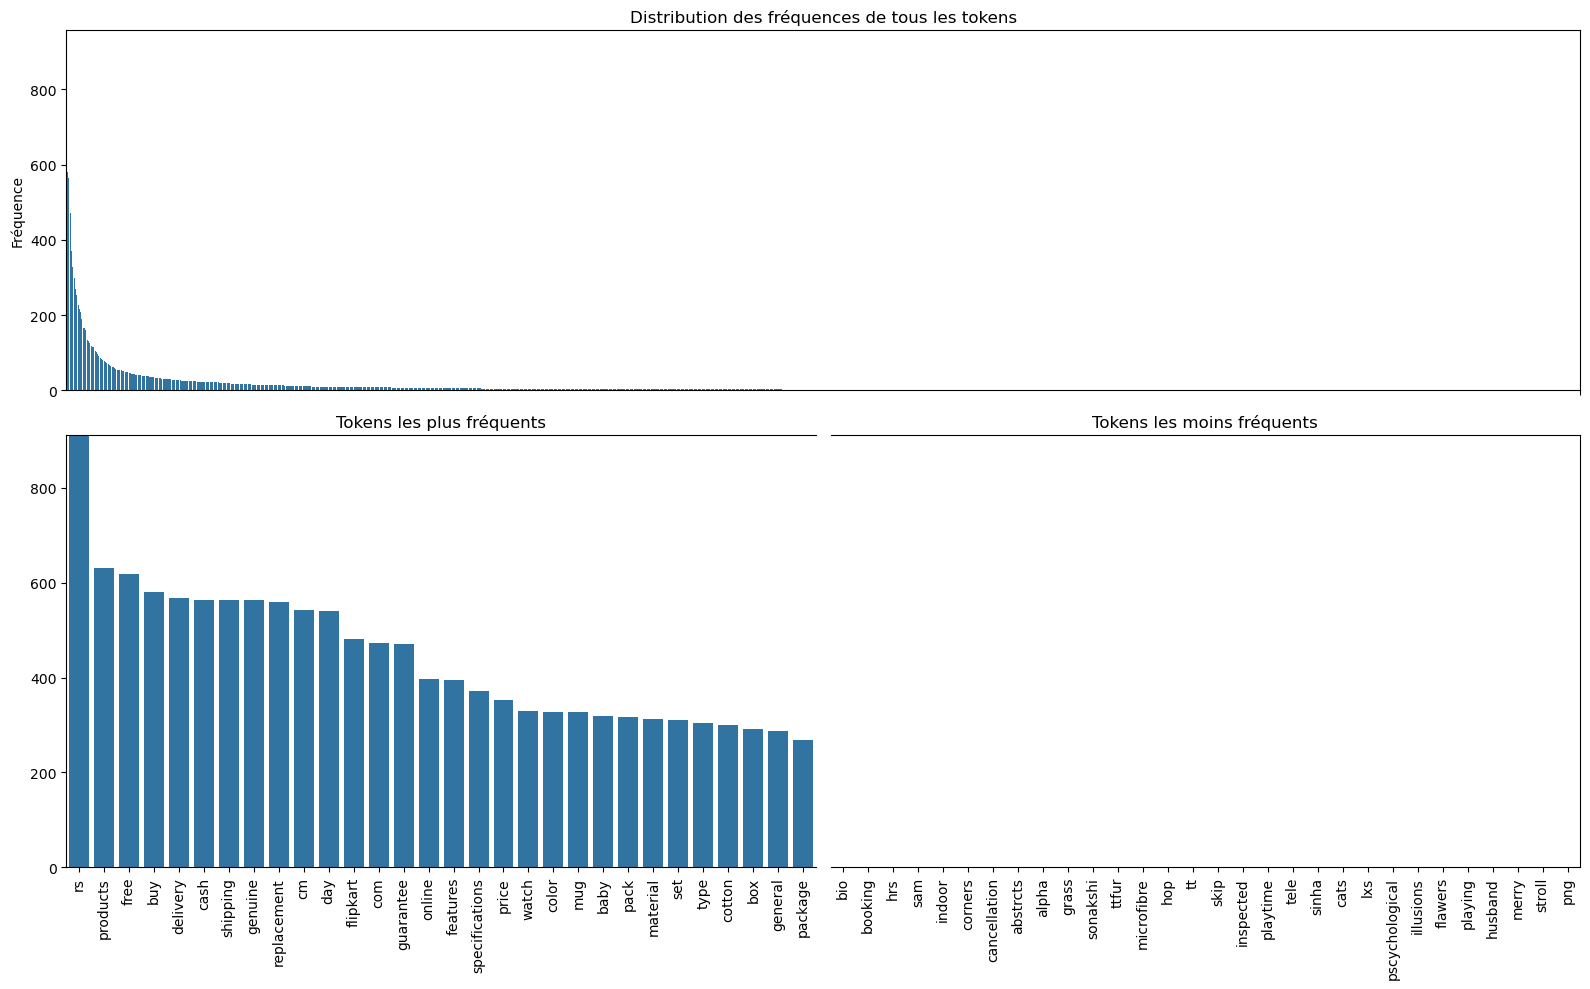

In [26]:
# Extraction des top30 et flop30 en terme de fréquence
top_30 = occ.head(30)
flop_30 = occ.tail(30)

# Création de la figure avec 2 lignes
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# 1. Graphique global
ax_global = fig.add_subplot(gs[0, :])
sns.barplot(x=occ.index, y=occ.values, ax=ax_global)
ax_global.set_title("Distribution des fréquences de tous les tokens")
ax_global.set_xticks([''])  
ax_global.set_xlabel("")
ax_global.set_ylabel("Fréquence")

# 2. Graphique top 30
ax1 = fig.add_subplot(gs[1, 0])
sns.barplot(x=top_30.index, y=top_30.values, ax=ax1)
ax1.set_xticks(range(len(top_30)))
ax1.set_xlabel("")
ax1.set_xticklabels(top_30.index, rotation=90)
ax1.set_title("Tokens les plus fréquents")

# 3. Graphique flop 30
ax2 = fig.add_subplot(gs[1, 1])
sns.barplot(x=flop_30.index, y=flop_30.values, ax=ax2)
ax2.set_xticks(range(len(flop_30)))
ax2.set_xlabel("")
ax2.set_xticklabels(flop_30.index, rotation=90)
ax2.set_title("Tokens les moins fréquents")

# Harmonisation de l’échelle des y entre les deux graphes
ymax = max(top_30.max(), flop_30.max())
ax1.set_ylim(0, ymax)
ax2.set_ylim(0, ymax)

# Suppression des bordures entre les deux graphes
ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)

# Conservation des echelles y uniquement à gauche
ax2.yaxis.set_visible(False)

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde du graphique
plt.savefig(f'../Output/Preprocessing_texte/Distribution des fréquences des tokens.png', format='png')

# Affichage de la figure
plt.show()

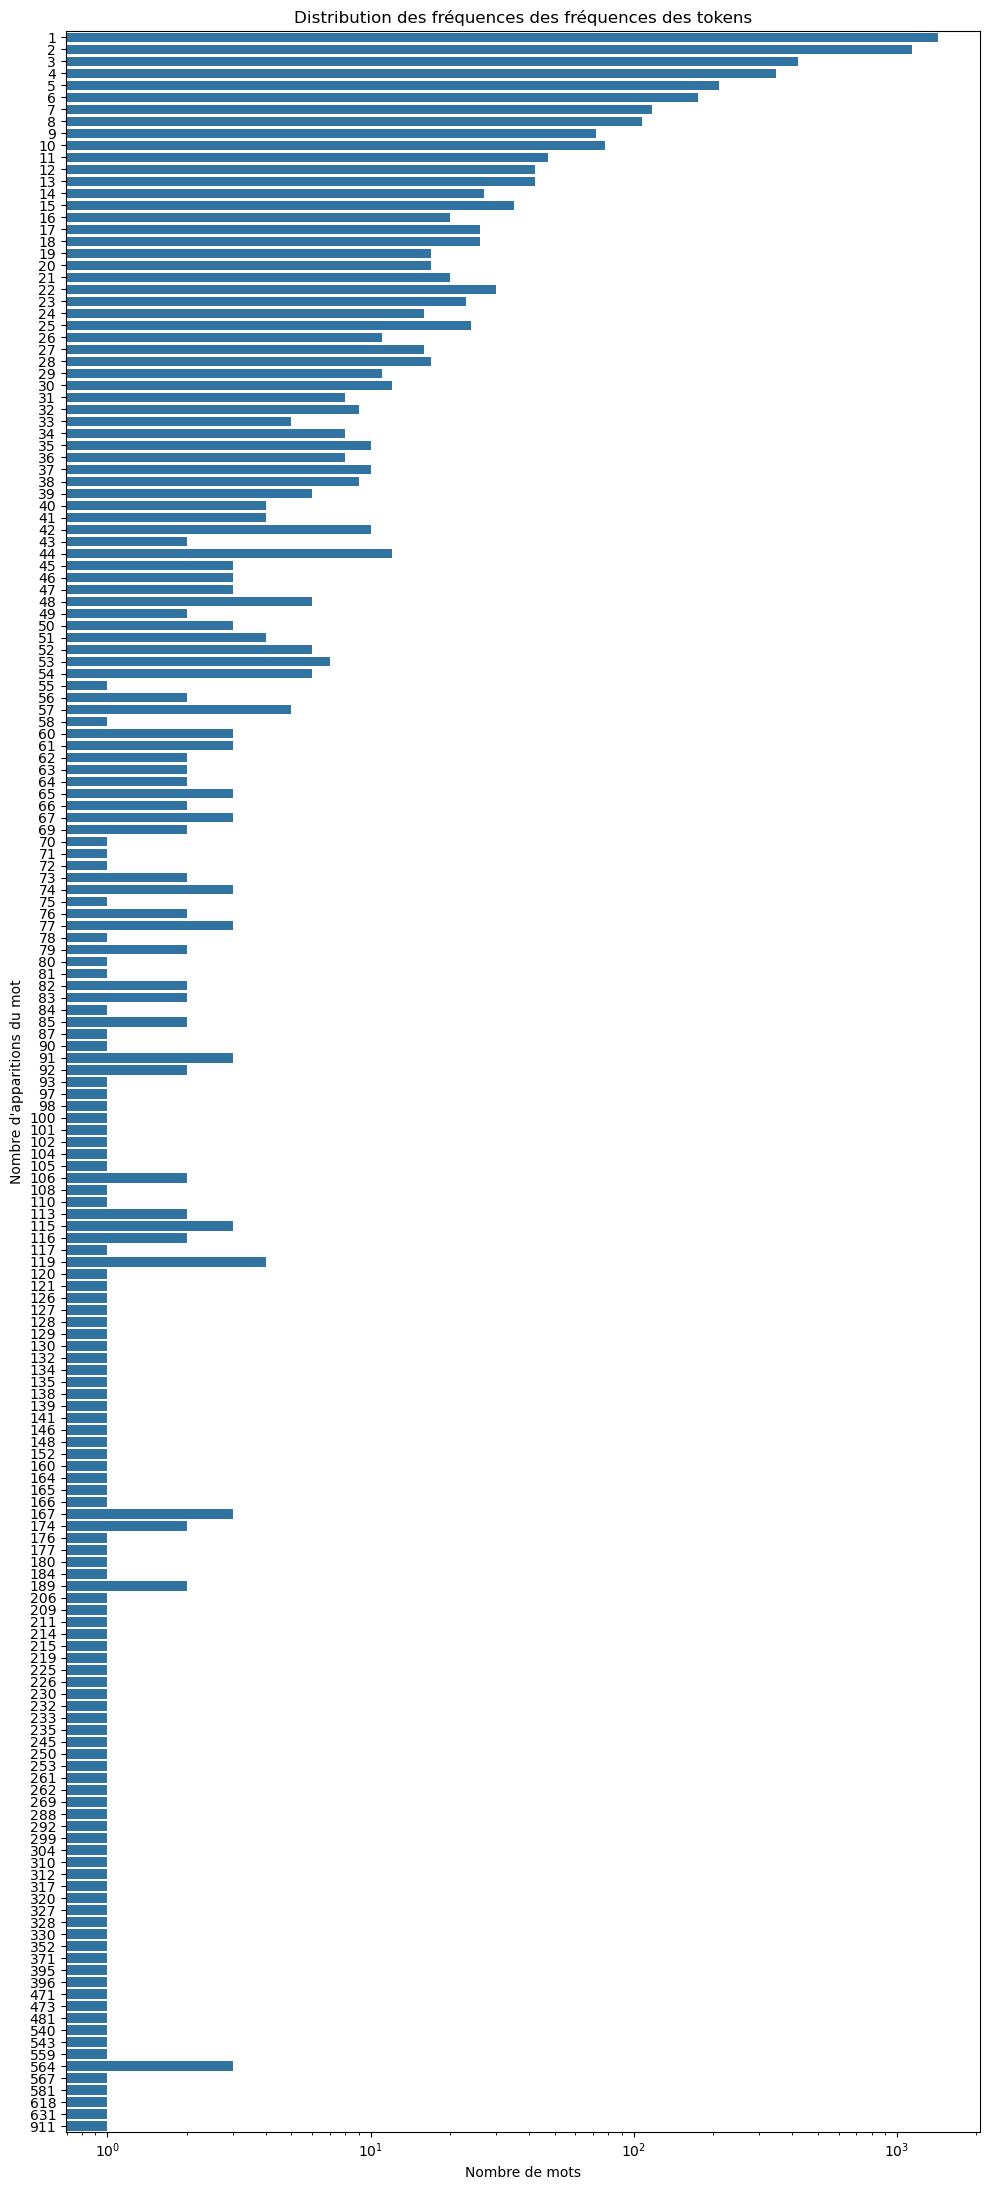

In [27]:
# Augmentention de la talle de la fenêtre d'affichage
display(HTML("<style>.output_scroll {height:auto !important; max-height: none !important;}</style>"))

# Calcule de la fréquence des fréquences
freq_of_freq = occ.value_counts().sort_index()

# Création de la DataFrame
df_freq = pd.DataFrame({
    'nb_apparitions': freq_of_freq.index.astype(str), 
    'nb_mots': freq_of_freq.values
})

# Construction du graphique
plt.figure(figsize=(10, 22))
sns.barplot(data=df_freq, y='nb_apparitions', x='nb_mots')

# Passage de l'échelle au logarithme pour améliorer la lisibilité du graphique
plt.xscale('log')

# Ajout des titres des axes
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre d'apparitions du mot")

# Ajout du titre de la figure
plt.title("Distribution des fréquences des fréquences des tokens")

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde du graphique
plt.savefig(f'../Output/Preprocessing_texte/Distribution des fréquences des fréquences tokens.png', format='png')

# Affichage de la figure
plt.show()


In [28]:
# Description statistique de la variable occ
occ.describe()

count    4897.000000
mean       11.358383
std        42.025849
min         1.000000
25%         1.000000
50%         2.000000
75%         6.000000
max       911.000000
Name: count, dtype: float64

Les différents graphiques confirment la présence d’un grand nombre de mots rares présents seulement une ou deux fois. En particulier, la table descriptive indique que plus de 25 % des mots n’apparaissent qu’une seule fois. Ces mots ne seront pas utiles et pourront être éliminés du vocabulaire du corpus car ils ne permettront pas de classer les produits en fonction de leur catégories. Afin d’évaluer l’impact de cette opération de filtrage sur l'étape de clustering et de comparaison des catégories réelles et prédites, on va définir deux listes de mots rares : une liste contenant les mots présents une seule fois et une liste contenant les mots présents au plus 3 fois.

In [29]:
# Liste de mot uniques 
low_frequency_words_1 = occ[occ==1]
low_frequency_words_1 = list(low_frequency_words_1.index)
len(low_frequency_words_1)

1436

In [30]:
# Liste de mot présents deux fois seulement 
low_frequency_words_3 = occ[occ<=3]
low_frequency_words_3 = list(low_frequency_words_3.index)
len(low_frequency_words_3)

2998

In [31]:
# Construction du corpus
raw_corpus = " ".join(Data_txt['description'].values)

# Visualisation du prétraietment avant filtrage des mots rares
tokens_corpus = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=None,
                   lemm_or_stemm=None,
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens_corpus)

nb tokens 52969, nb tokens uniques 4781
['key', 'features', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'height', 'pack', 'price', 'curtain', 'enhances', 'look', 'interiors', 'curtain', 'made', 'high', 'quality', 'polyester']


In [32]:
# Construction du corpus
raw_corpus = " ".join(Data_txt['description'].values)

# Ajout de l'étape de filtrage des mots uniques
tokens_corpus = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm=None,
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens_corpus)


nb tokens 51562, nb tokens uniques 3374
['key', 'features', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'height', 'pack', 'price', 'curtain', 'enhances', 'look', 'interiors', 'curtain', 'made', 'high', 'quality', 'polyester']


Le filtrage des mots rares n'apparaissant qu'une seule fois dans l'ensemble du corpus a permis de passer de 52929 tokens à 51562 tokens, soit une diminution d’environ 2,6 %. L'utilisation de cette liste de mots rare pourrait permettre d’éliminer le bruit dans les données textuelles des descriptions, en supprimant les termes peu représentatifs qui n’apporterait pas des informations utiles pour les modèles de clustering ou de classification.

In [33]:
# Construction du corpus
raw_corpus = " ".join(Data_txt['description'].values)

# Ajout de l'étape de filtrage des mots présents au plus 3 fois
tokens_corpus = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_3,
                   lemm_or_stemm=None,
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Appel de la fonction display_token_info
display_token_info(tokens_corpus)


nb tokens 48111, nb tokens uniques 1851
['key', 'features', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'height', 'pack', 'price', 'curtain', 'enhances', 'look', 'interiors', 'curtain', 'made', 'high', 'quality', 'polyester']


Après avoir établie une liste de mots rare on peut également s'intéresser aux mots les plus fréquents. Il faudra faire la différence entre les mots génériques, c'est à dire ceux qui sont fréquents car présents dans l'ensemble des catégories, des mots fréquents car très spécifique d'une catégorie. Ces derniers seront utiles tandis que les autres ne le seront pas. En plus des visualisations en count plot, la fréquence des mots peut aussi être visualisée grace a une représentation graphique de type wordcloud. Ce type de représentation graphique permet de visualiser rapidement les mots les plus fréquents.

On va tout d’abord s’intéresser au wordcloud représentant l’ensemble du corpus, afin d’avoir une vue globale des mots les plus fréquents dans nos descriptions. Puis on pourra analyser les wordclouds spécifiques à chacune des catégories, ce qui permettra de mieux comprendre les particularités lexicales propres à chaque groupe. Afin d'évaluer l'impact de la phase de prétraitement on visualisera deux versions du wordcloud: l'une basée sur les données brutes et l'autres issue des données prétraitées.

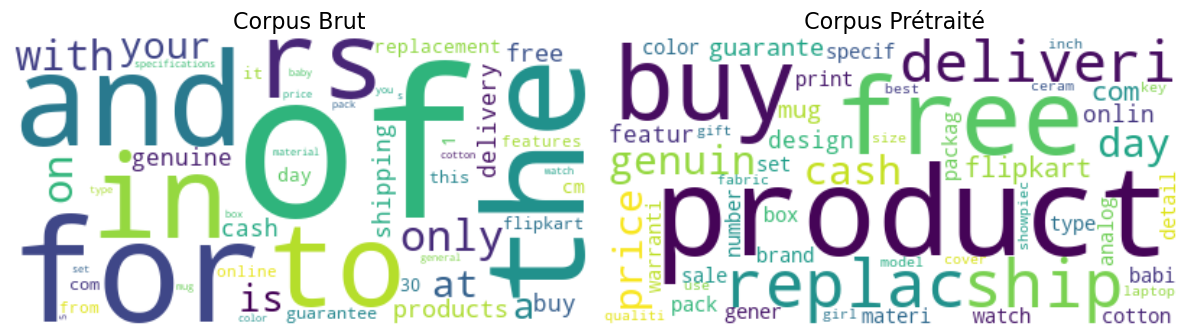

In [34]:
# Construction de la figure
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Définition du tokenizer
tokenizer = RegexpTokenizer(r"\w+")
    
# Tokenisation simple du texte brut
tokens_raw = tokenizer.tokenize(raw_corpus.lower())
    
# Calcul de la fréquence des tokens
freq_raw = Counter(tokens_raw)
    
# Construction du premier wordcloud sur les données brutes
wc_raw = WordCloud(background_color='white', max_words=50).generate_from_frequencies(freq_raw)
axes[0].imshow(wc_raw, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title(f'Corpus Brut', fontsize=16)

# Prétraitement du corpus
cleaned_corpus = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm='stemm',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=None)

# Calcul de la fréquence de chaque mots
freq_preprocess = Counter(cleaned_corpus)

# Construction du wordcloud sur les données prétraitées
wc_preprocess = WordCloud(background_color='white', max_words=50).generate_from_frequencies(freq_preprocess)
axes[1].imshow(wc_preprocess, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title(f' Corpus Prétraité', fontsize=16)

# Ajustement du graphique
plt.tight_layout()

# Sauvegarde du graphique
plt.savefig(f'../Output/Preprocessing_texte/Wordclouds_corpus(avant_et_apres_prétraitement).png', format='png')

# Affichage du graphique
plt.show()

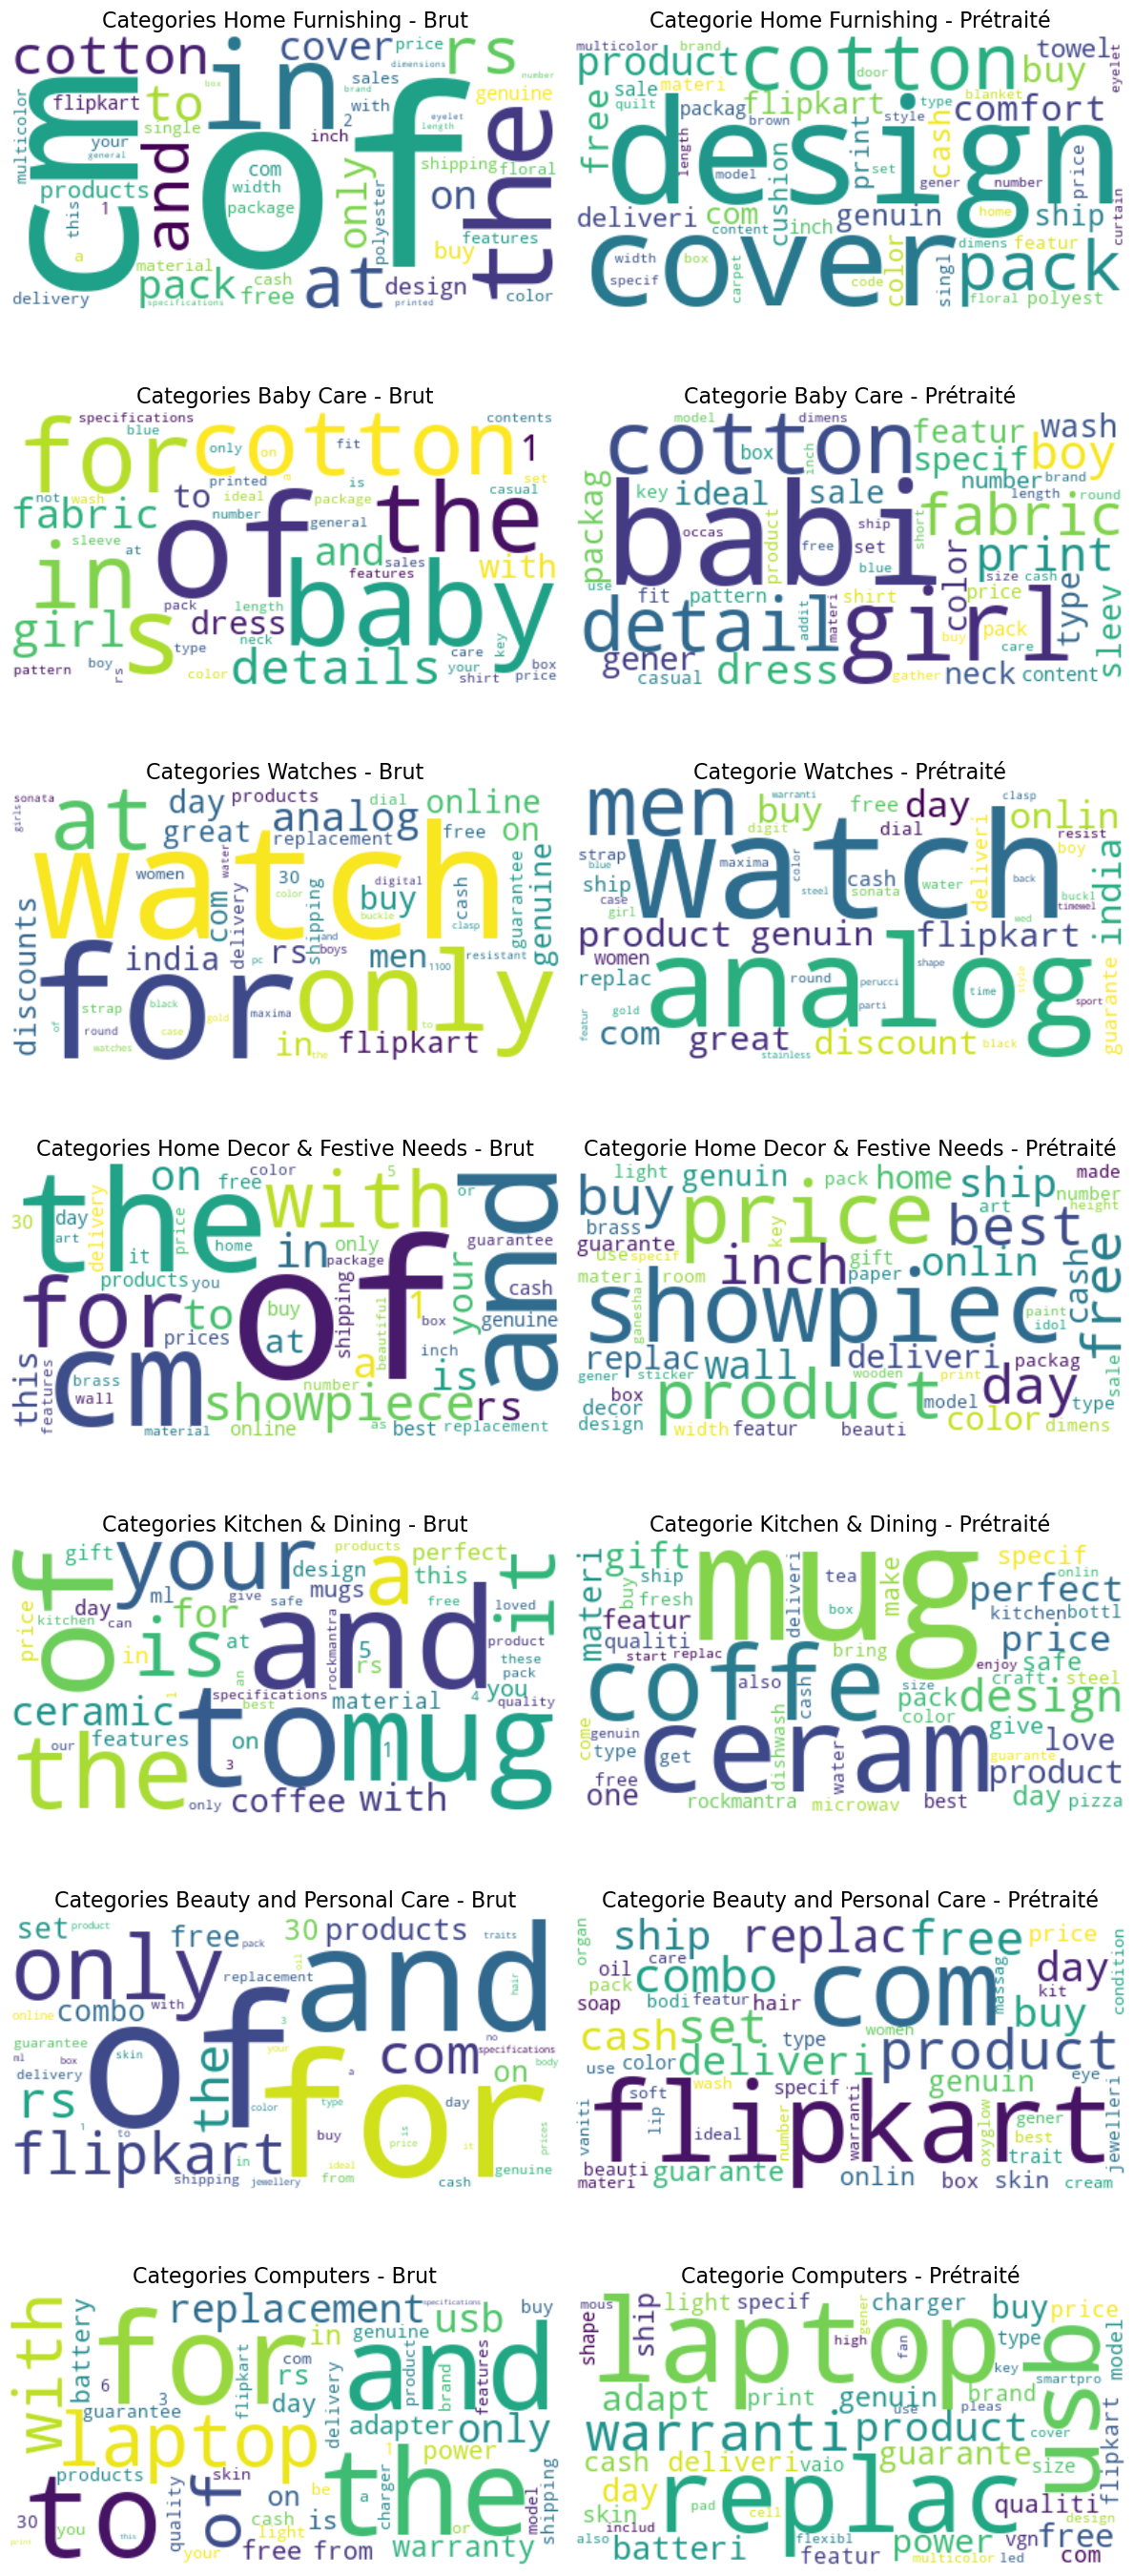

In [35]:
# Augmentention de la talle de la fenêtre d'affichage
display(HTML("<style>.output_scroll {height:auto !important; max-height: none !important;}</style>"))

# Liste des catégories
categories = Data_txt['First_category'].unique()

# Initialisation du dictionnaire
corpus_preprocessed = {}

# Construction d'un dictionnaire contenant les description de chaque catégorie avant prétraitement
raw_corpus = {label: ' '.join(Data_txt[Data_txt['First_category'] == label]['description']) for label in categories}

# Construction de la figure
fig, axes = plt.subplots(len(categories), 2, figsize=(12, 4*len(categories)))

# Pour chaque catégorie
for i, label in enumerate(categories):
    
    # Définition du tokenizer
    tokenizer = RegexpTokenizer(r"\w+")
    
    # Tokenisation simple du texte brut
    tokens_raw = tokenizer.tokenize(raw_corpus[label].lower())
    
    # Calcul de la fréquence des tokens
    freq_raw = Counter(tokens_raw)
    
    # Wordcloud sur données brutes (fréquences)
    wc_raw = WordCloud(background_color='white', max_words=50).generate_from_frequencies(freq_raw)
    axes[i, 0].imshow(wc_raw, interpolation='bilinear')
    axes[i, 0].axis('off')
    axes[i, 0].set_title(f'Categories {label} - Brut', fontsize=16)

    # Prétraitement des données
    cleaned_text = process_text(
        raw_corpus[label],
        stop_words,
        rejoin=False,
        list_of_rare_words=low_frequency_words_1,
        lemm_or_stemm='stemm',
        min_len_words=3,
        force_is_alpha=True,
        eng_words=None,
        common_words=None
    )
    
    # Ajout des données prétraitées dans le dictionnaire
    corpus_preprocessed[label] = cleaned_text
    
    # Calcul des fréquences des tokens prétraités
    freq_preprocess = Counter(cleaned_text)

    # Construction du deuxième wordcloud sur les données prétraitées
    wc_pre = WordCloud(background_color='white', max_words=50).generate_from_frequencies(freq_preprocess)    
    axes[i, 1].imshow(wc_pre, interpolation='bilinear')
    axes[i, 1].axis('off')
    axes[i, 1].set_title(f'Categorie {label} - Prétraité', fontsize=16)

# Ajustement de la figure
plt.tight_layout()

# Sauvegarde du graphique
plt.savefig(f'../Output/Preprocessing_texte/Wordclouds_catégories(avant_et_apres_prétraitement).png', format='png')

# Affichage du graphique
plt.show()

La figure ci dessus permet de visualiser l’impact des différentes étapes de transformation textuelle sur la fréquence des mots par catégorie. Elle met en évidence la manière dont certaines transformations (comme la suppression des stopwords ou la transformation des mots à le forme racinaire) affectent la répartition du vocabulaire dans chaque groupe. En particulier, on remarque que sans prétraitement, les mots qui apparaissent comme étant les plus représentés dans la plupart des catégories correspondent aux stopwords.

Cette représentation permet également de retrouver des mots très fréquents dans l’ensemble du corpus, tels que product, qui apparaissent dans plusieurs catégories. Ces mots sont souvent peu discriminants, car ils sont communs à plusieurs classes et n’apportent pas d’information spécifique permettant de différencier les produits selon leur catégorie. On va donc mettre en place deux nouvelles listes stockant ces mots communs à différentes catégories. 

La première liste correspondra au mots présents dans le top 50 de toutes les catégories tandis que la deuxième liste correspondra aux mots présents dans le top 50 d'au moins 4 catégories. 

In [36]:
# top 50
n = 50  

# Initialisation du dictionnaire contenant les top mots par catégorie
top_words_par_category = {}

# Pour chaque categorie et tokens
for cat, tokens in corpus_preprocessed.items():
    
    # Compte du nombre de fois où le token apparait
    counts = Counter(tokens)
    top_words = [word for word, count in counts.most_common(n)]
    top_words_par_category[cat] = set(top_words)

# Construction de la liste de mots communs à toutes les catégories
mots_communs_7 = set.intersection(*top_words_par_category.values())

# Affichage du nombre de mots commun et de la liste de token
print(f"Mots communs aux {len(top_words_par_category)} clusters (top {n}):", mots_communs_7)


# Construction d'une liste de mots communs à k catégories
k = 4

# Liste des ensembles de top mots
sets_top_words = list(top_words_par_category.values())

# Compte du nombre de catégories dans lesquelles chaque mot apparaît
word_counts = Counter(word for s in sets_top_words for word in s)

# Mots présents dans au moins k catégories
mots_communs_4 = [word for word, count in word_counts.items() if count >= k]

# Affichage du nombre de mots commun et de la liste de token
print(f"Mots présents dans au moins {k} clusters:", mots_communs_4)


Mots communs aux 7 clusters (top 50): {'ship', 'cash', 'product', 'featur', 'buy', 'free'}
Mots présents dans au moins 4 clusters: ['materi', 'flipkart', 'pack', 'model', 'product', 'featur', 'free', 'print', 'price', 'specif', 'ship', 'buy', 'type', 'number', 'gener', 'box', 'design', 'cash', 'genuin', 'deliveri', 'com', 'color', 'use', 'guarante', 'day', 'replac', 'onlin']


### Analyse des mots non anglais

Une dernière étape de nettoyage souvent utilisée consiste à supprimer les mots qui ne figurent pas dans un dictionnaire de mots de la langue utilisée dans le corpus (ici l'anglais). Cependant, dans le cas du présent projet, cette approche pourrait ne pas être pertinente, car il est possible que certains mots spécifiques d'une catégorie tel qu'une marque ou un terme technique ne soient pas présent dans le répertoire de mots anglais. On va donc tester cette approche et analyser les mots qui sont retirés pour conclure sur la pertinence de cette étape. Afin d'analyser les mots non anglais éliminées, on se basera sur les mots non anglais stemmés et lémantisés.

In [37]:
# Liste des mots anglais
eng_words = [i.lower() for i in words.words()]

In [38]:
# Instantiation du stemmer
stemmer = PorterStemmer()

# Stemming des mots anglais
eng_words_stem = [stemmer.stem(i) for i in eng_words]

# Appel de la fonction display token info
display_token_info(eng_words_stem)

nb tokens 236736, nb tokens uniques 178311
['a', 'a', 'aa', 'aal', 'aalii', 'aam', 'aani', 'aardvark', 'aardwolf', 'aaron', 'aaron', 'aaron', 'aaronit', 'aaronit', 'aaru', 'ab', 'aba', 'ababdeh', 'ababua', 'abac', 'abaca', 'abac', 'abacay', 'abacin', 'abacin', 'abaciscu', 'abacist', 'aback', 'abactin', 'abactin']


In [39]:
# Instantiation du lementasier
lementizer = WordNetLemmatizer()

# Lemmentization des mots anglais
eng_words_lem = [lementizer.lemmatize(i) for i in eng_words]

# Appel de la fonction display token info
display_token_info(eng_words_lem)

nb tokens 236736, nb tokens uniques 233517
['a', 'a', 'aa', 'aal', 'aalii', 'aam', 'aani', 'aardvark', 'aardwolf', 'aaron', 'aaronic', 'aaronical', 'aaronite', 'aaronitic', 'aaru', 'ab', 'aba', 'ababdeh', 'ababua', 'abac', 'abaca', 'abacate', 'abacay', 'abacinate', 'abacination', 'abaciscus', 'abacist', 'aback', 'abactinal', 'abactinally']


In [40]:
# Construction du corpus
raw_corpus = " ".join(Data_txt['description'].values)

# Ajout de l'étape de suppression des mots anglais après stemming
corpus_wo_non_eng_stem_words = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm='stemm',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=eng_words_stem,
                   common_words=mots_communs_7)

# Suppresion de l'étape de suppression des mots anglais après stemming
corpus_with_non_eng_stem_words = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm='stemm',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=mots_communs_7)

# Appel de la fonction display token info
display_token_info(corpus_wo_non_eng_stem_words)

nb tokens 42862, nb tokens uniques 2168
['key', 'eleg', 'polyest', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'eleg', 'polyest', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'height', 'pack', 'price', 'curtain', 'enhanc', 'look', 'interior', 'curtain', 'made', 'high', 'qualiti', 'polyest', 'fabric']


In [41]:
# Conversion en ensembles
tokens_with = set(corpus_with_non_eng_stem_words)
tokens_wo = set(corpus_wo_non_eng_stem_words)

# Listes des mots supprimés par le filtre
removed_tokens = tokens_with - tokens_wo

# Affichage du nombre de mots non anglais supprimés et d'un exemple de 20 mots
print(f"{len(removed_tokens)} tokens ont été supprimés par le filtre anglais.")
print("Exemples :", list(removed_tokens)[:20], '\n')

# Calcul de la fréquence d'apparition des mots supprimés
freq_corpus = Counter(corpus_with_non_eng_stem_words)

# Tri des mots supprimés selon leur fréquence d'apparition
removed_tokens_sorted = sorted(removed_tokens, key=lambda x: freq_corpus[x], reverse=True)

# Affichage des 20 mots supprimés les plus fréquents
for w in removed_tokens_sorted[:20]:
    print(f"{w} → {freq_corpus[w]} fois")


574 tokens ont été supprimés par le filtre anglais.
Exemples : ['teflon', 'nirlon', 'jewelkraft', 'tigi', 'intel', 'nikunj', 'printland', 'gm', 'usb', 'polyresin', 'dia', 'aari', 'myesquir', 'cookart', 'everytim', 'tricolosan', 'vaccum', 'rtd', 'shaun', 'jutebag'] 

flipkart → 481 fois
com → 473 fois
onlin → 396 fois
laptop → 234 fois
usb → 174 fois
combo → 148 fois
women → 139 fois
rockmantra → 65 fois
bedsheet → 59 fois
vgn → 53 fois
vaio → 53 fois
kadhai → 45 fois
multi → 44 fois
smartpro → 44 fois
prithish → 41 fois
printland → 38 fois
jewelleri → 37 fois
ganesha → 36 fois
lapguard → 33 fois
nutcas → 29 fois


Les termes non anglais supprimés qui reviennent le plus dans le corpus spnt les terme flipkart qui correspond au nom du site de vente en ligne ainsi que le terme com qui correspond probablement au .com d'une adresse URL. Il est étonnant que ces deux termes n'aient pas été supprimés grâce au filtrage des mots communs. On va regarder a quel fréquence ils apparaissaient dans chacune des catégorie. En revanche, on peut remarquer que certains mots supprimés et fréquents semblent spécifiques à certaines catégories. Par exemple le terme laptop semble au vu de son sens associé à la catégorie computer. Vaio étant une marque d'ordinateur est également probablement un mot non anglais spécifique de la catégorie computer. Cela nous indique qu'il n'est probablement pas pertinent de filtrer les mots non anglais.

In [42]:
# Dictionnaire pour stocker les fréquences par catégorie
freq_per_category = {}

# Pour chaque catégorie et token
for category, token in corpus_preprocessed.items():
   
    # Calcul des fréquences de mots dans le texte
    freq = Counter(token)
    
    # Calcul de la fréquence par catégorie 
    freq_per_category[category] = freq
    
# Définition des token à analyser
liste_tokens = ['flipkart', 'com', 'vaio', 'laptop']

# Pour chaque token de la liste, affichage de sa fréquence dans les différentes catégories
for tok in liste_tokens :
    print('\n')
    for category, freq in freq_per_category.items():
        print(f"Catégorie: {category} - Fréquence de '{tok}': {freq.get(tok, 0)}")




Catégorie: Home Furnishing - Fréquence de 'flipkart': 74
Catégorie: Baby Care - Fréquence de 'flipkart': 32
Catégorie: Watches - Fréquence de 'flipkart': 134
Catégorie: Home Decor & Festive Needs - Fréquence de 'flipkart': 2
Catégorie: Kitchen & Dining - Fréquence de 'flipkart': 8
Catégorie: Beauty and Personal Care - Fréquence de 'flipkart': 163
Catégorie: Computers - Fréquence de 'flipkart': 68


Catégorie: Home Furnishing - Fréquence de 'com': 74
Catégorie: Baby Care - Fréquence de 'com': 32
Catégorie: Watches - Fréquence de 'com': 134
Catégorie: Home Decor & Festive Needs - Fréquence de 'com': 0
Catégorie: Kitchen & Dining - Fréquence de 'com': 6
Catégorie: Beauty and Personal Care - Fréquence de 'com': 159
Catégorie: Computers - Fréquence de 'com': 68


Catégorie: Home Furnishing - Fréquence de 'vaio': 0
Catégorie: Baby Care - Fréquence de 'vaio': 0
Catégorie: Watches - Fréquence de 'vaio': 0
Catégorie: Home Decor & Festive Needs - Fréquence de 'vaio': 0
Catégorie: Kitchen & Din

 On remarque en effet que les termes flipkart et com n'ont pas été filtrés car ils figuraient dans le top 50 de seulement 4 catégorie sur 7. Ils le seront si on utilise la deuxième liste moins stricte de mots communs. De même l'analyse de la fréquence des mots laptop et vaio confirme que ce sont des mots spécifiques à la catégorie computer et qu'il ne serait pas pertinent de les éliminer. Pour la suite, on n'utilisera donc pas la liste des mots anglais pour supprimer les mots non anglais de manière à conserver ces termes spécifiques et pertinents pour l'étape de clustering et de classification.

In [43]:
# Ajout de l'étape de suppression des mots anglais après lemmentisation
corpus_wo_non_eng_lem_words = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm='lem',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=eng_words_lem,
                   common_words=mots_communs_7)

# Suppresion de l'étape de suppression des mots anglais après stemming
corpus_with_non_eng_lem_words = process_text(raw_corpus, stop_words, rejoin=False,
                   list_of_rare_words=low_frequency_words_1,
                   lemm_or_stemm='lem',
                   min_len_words=3,
                   force_is_alpha=True,
                   eng_words=None,
                   common_words=mots_communs_7)

# Appel de la fonction display token info
display_token_info(corpus_wo_non_eng_lem_words)

nb tokens 42537, nb tokens uniques 2336
['key', 'feature', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'floral', 'curtain', 'elegance', 'polyester', 'multicolor', 'abstract', 'eyelet', 'door', 'curtain', 'height', 'pack', 'price', 'curtain', 'look', 'interior', 'curtain', 'made', 'high', 'quality', 'polyester', 'fabric']


In [44]:
# Conversion en ensembles
tokens_with = set(corpus_with_non_eng_lem_words)
tokens_wo = set(corpus_wo_non_eng_lem_words)

# Listes des mots supprimés par le filtre
removed_tokens = tokens_with - tokens_wo

# Affichage du nombre de mots non anglais supprimés et d'un exemple de 20 mots
print(f"{len(removed_tokens)} tokens ont été supprimés par le filtre anglais.")
print("Exemples :", list(removed_tokens)[:20], '\n')

# Calcul de la fréquence d'apparition des mots supprimés
freq_corpus = Counter(corpus_with_non_eng_lem_words)

# Tri des mots supprimés selon leur fréquence d'apparition
removed_tokens_sorted = sorted(removed_tokens, key=lambda x: freq_corpus[x], reverse=True)

# Affichage des 20 mots supprimés les plus fréquents
for w in removed_tokens_sorted[:20]:
    print(f"{w} → {freq_corpus[w]} fois")

759 tokens ont été supprimés par le filtre anglais.
Exemples : ['teflon', 'nirlon', 'socialise', 'promotes', 'jewelkraft', 'tigi', 'intel', 'nikunj', 'printland', 'gm', 'usb', 'polyresin', 'dia', 'marketplace', 'barbie', 'aari', 'occassions', 'cookart', 'tricolosan', 'vaccum'] 

flipkart → 481 fois
com → 473 fois
online → 396 fois
analog → 262 fois
laptop → 234 fois
usb → 174 fois
combo → 148 fois
loved → 77 fois
rockmantra → 65 fois
bedsheet → 57 fois
vgn → 53 fois
vaio → 53 fois
kadhai → 45 fois
ensuring → 44 fois
multi → 44 fois
smartpro → 44 fois
crafting → 42 fois
prithish → 41 fois
printland → 38 fois
gathered → 38 fois


Lorsqu’on utilise la liste de mots anglais lemmatisés, les mots supprimés sont très similaires à ceux supprimés avec la liste de mots anglais stemmés. Les mêmes interprétations et conclusions peuvent donc être faites dans ce cas.

## Nettoyage final des descriptions

Maintenant que les étapes de nettoyage et de prétraitement des descriptions ont été analysées, on peut appliquer celles qui se sont révélées les plus pertinentes au cours de cette première phase d’analyse.

In [45]:
# Application de la fonction de prétraitement
Data_txt['_Cleaned_desc'] = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_1,
                          lemm_or_stemm='lem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_7)
)


Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

In [46]:
# Affichage de 5 lignes aléatoires
Data_txt.sample(5)[['description', '_Cleaned_desc', 'First_category']]

,description,_Cleaned_desc,First_category
uniq_id,,,
32cf0691248297655e2c1728b12e2262,Poppins Printed Baby Boy's Jumpsuit\r\n ...,printed baby boy jumpsuit price high quality f...,Baby Care
285075cfac3036e8d51591dfe5ba24ab,Buy Raymond Abstract Double Blanket Pink at Rs...,raymond abstract double blanket pink flipkart ...,Home Furnishing
d0e09eaa7fcc9e7de3349959800d2141,HMT OLSS 01 Analog Watch - For Women - Buy HM...,hmt olss analog watch woman hmt olss analog wa...,Watches
5338c00e0ddaec0f3af737077e0bbd91,Timewel 1100-N1949_B Analog Watch - For Women...,timewel analog watch woman timewel analog watc...,Watches
60efd61370e70267dc60b11ff2bf974c,Buy Prithish Abstract Design 40 Ceramic Mug fo...,prithish abstract design ceramic mug online pr...,Kitchen & Dining


# Extraction de features 

Une fois les données textuelles des descriptions de produits nettoyées et prétraitées, il est nécessaire d’extraire des caractéristiques numériques exploitables par un modèle de clustering ou de classification. Pour cela, il faut encoder ces informations textuelles sous forme de vecteurs numériques. Cet encodage peut se faire grâce à différentes techniques plus ou moins complexes. 

Les méthodes les plus simples sont le Bag of Words (sac de mots) et le TF-IDF, qui représentent les textes par des vecteurs basés sur la fréquence des mots. D’autres approches plus avancées utilisent des représentations sémantiques plus riches, comme Word2Vec, les modèles basés sur les Transformers, ainsi que des architectures spécifiques telles que BERT (Bidirectional Encoder Representations from Transformers) ou USE (Universal Sentence Encoder). Chacune de ces méthodes sera présentée et expliquée en détail lorsqu’elle sera utilisée pour la première fois.

Dans la suite des analyses, on va évaluer l’impact des différentes méthodes d’extraction de features en projetant les caractéristiques extraites sur un espace dimensionnel à l’aide de la méthode t-SNE, puis en réalisant une segmentation des données dont les dimensions auront été préalablement réduites, également par t-SNE. La réduction de dimension permet de rendre les données visuellement interprétables, en facilitant leur représentation graphique en 2D, tout en conservant autant que possible la structure locale des données dans l’espace d’origine. Bien que le t-SNE ne conserve pas les distances globales des différents produits cela reste une approche efficace pour obtenir rapidement une visualisation qualitative de la structure des données, ce qui justifie son utilisation dans le cadre de cette étude exploratoire.

## Définition d'une fonction d'évaluation

In [47]:
def clustering_and_evaluation(feature_tsne, df, method, n_clusters=7, verbose=False, title="Evaluation clustering"):
    """
    Évalue la qualité d’un clustering par KMeans sur des données réduites par t-SNE, 
    puis affiche les résultats avec une visualisation 2D et calcule le score ARI.

    Paramètres :
        feature_tsne (array (n_samples, n_features)) : Matrice de caractéristiques à évaluer.
        df (pandas.DataFrame) : DataFrame contenant la colonne avec les catégories réelles des produits.
        method (str): Nom de la méthode ou du modèle utilisé pour extraire les features
        n_clusters (int) : Nombre de clusters à utiliser pour le clustering KMeans.
        verbose (bool) : Affichage ou non d'informations.
        title (str) : Titre de la figure affichée.
    """
        
    # Clustering sur les données du TSNE
    cls = KMeans(n_clusters=n_clusters, n_init=100, random_state=6)
    cls.fit(feature_tsne)
    y_pred = cls.labels_
    
    # Calcul du score ARI
    y_true = df["First_category"].reset_index(drop=True)
    ari = adjusted_rand_score(y_true, y_pred)

    # Si demandé, affichage des résultats
    if verbose:
        print(f'===== {title}===== ')
        print(f"ARI : {ari:.4f}")
    
    # Dataframe pour le plot
    df_tsne = pd.DataFrame(feature_tsne, columns=["tsne1", "tsne2"]).reset_index(drop=True)
    df_tsne["true_label"] = y_true
    df_tsne["cluster_label"] = y_pred.astype(str)
    
    # Création de la figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot 1 : vrais labels
    sns.scatterplot(ax=axes[0], data=df_tsne, x="tsne1", y="tsne2", hue="true_label", palette="tab10", s=30, alpha=0.8)
    axes[0].set_title("True labels (t-SNE)")
    axes[0].set_xlabel("t-SNE 1")
    axes[0].set_ylabel("t-SNE 2")
    axes[0].legend(title="True labels", loc="best", fontsize=9)

    # Plot 2 : clusters KMeans
    sns.scatterplot(ax=axes[1], data=df_tsne, x="tsne1", y="tsne2", hue="cluster_label", palette="tab10", s=30, alpha=0.8)
    axes[1].set_title("Cluster labels (t-SNE)")
    axes[1].set_xlabel("t-SNE 1")
    axes[1].set_ylabel("t-SNE 2")
    axes[1].legend(title="Clusters", loc="best", fontsize=9)

    # Titre général
    fig.suptitle('Projection 2D des features', fontsize=14)

    # Ajustement layout
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    # Sauvegarde du graphique
    plt.savefig(f'../Output/Extraction_de_features_texte/Evaluation_clustering_({method}).png', format='png')

    # Affichage de la figure
    plt.show()
    
    return ari


## Analyse des différentes approches d'extraction de features

### Bag of Words

Une méthode simple d'extraction de feature correspond à la construction d'un Bag of Words ou BoW qui permet de représenter un texte sous forme vectorielle de manière a tenir compte de la fréquence des mots dans un document. On va commencer par lister tous les mots présents dans le corpus puis on comptera le nombre d'occurence de chaque mots dans chaque documents. Les documents seront finalement représenté par un vecteur de comptage de ces mots. (Ici un document = une description). Plusieurs paramètres sont ajustables. En particulier on peux fixer le nombre de mots à utiliser pour construire les vecteurs en ajustant le paramètre max_features qui limitent le nombre de mots du vocabulaire aux N mots les plus fréquents. 

Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

===== BoW + TSNE + KMeans===== 
ARI : 0.4138


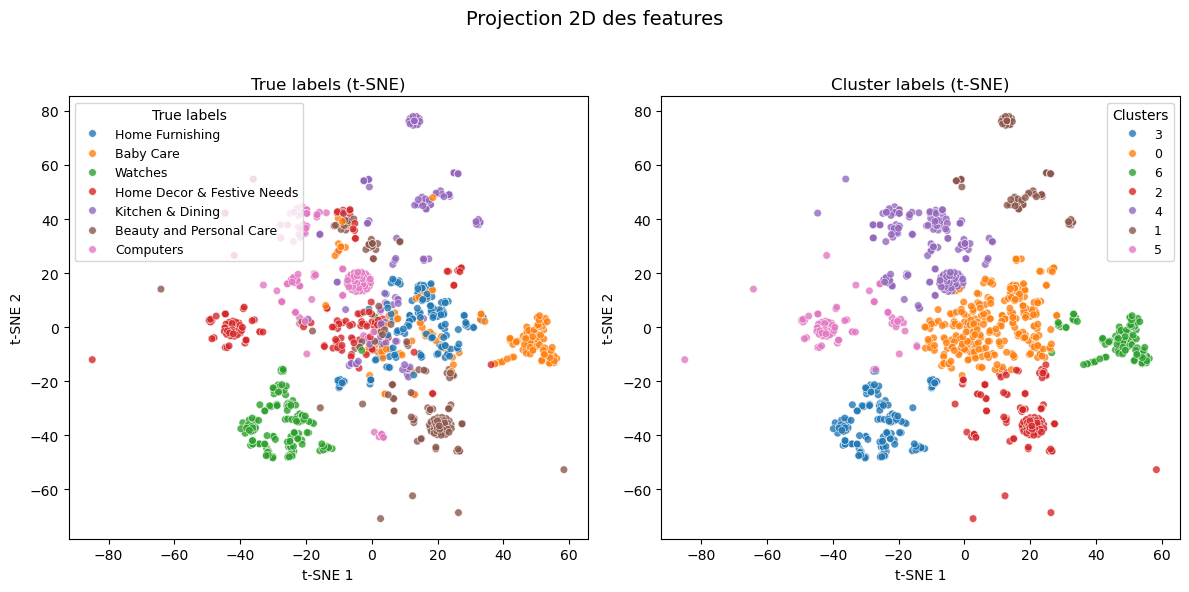

In [48]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_1,
                          lemm_or_stemm='stem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_4)
)

# Extraction du temps avant l'extraction de features
start = time.time()

# Paramétrage de la fonction d'extraction de features
vectorizer = CountVectorizer(max_features=200)

# Transformation des textes
features = vectorizer.fit_transform(desc_cleaned)
features_dense = features.toarray() 

# Calcul du temps d'extraction de feature
duration_bow = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)

# Réduction de la dimensionnalité des features
features_tnse = tsne.fit_transform(features_dense)

# Appel de la fonction d'évaluation 
ari_bow = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "Bag_of_words",
                    n_clusters=7, 
                    verbose=True, 
                    title="BoW + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_bow = pd.DataFrame({
    'approche': ['BOW'],
    'ari': [ari_bow],
    "temps d'execution": [duration_bow]
})

# Ajout des résulats de l'approche BoW dans la dataframe contenant tous les résultats 
Resultats = pd.DataFrame(Resultats_bow)

La projection des vecteurs issus du bag of word sur un espace en deux dimension met en évidence que certains produits comme les montres ont tendance à bien se regrouper. Cette catégorie est également bien retrouvée par l’algorithme de segmentation mais le cluster correspondant récupère en plus quelques produits de la catégorie Home Furnishing. Concernant les autres catégories, le regroupement est plus variable : une majorité de produits semblent correctement rassemblés selon leur catégorie, mais on observe également des chevauchements entre certaines catégories. Certains produits apparaissent ainsi mélangés à d’autres catégorie, ce qui suggère soit une proximité sémantique dans leur description, soit une limite de la représentation BoW ou du clustering dans ce cas.

### TF IDF 

Une variante de la méthode BoW présenté à la section précédente correspond au TF-IDF qui premet d'améliorer le BoW en pondérant chaque mot selon leur importance locale et globale. La fréquence locale mesure l'importance d'un mots dans un document donné. Plus un mot apparait souvent dans un document, plus il est jugé important pour ce document. La fréquence inverse des documents quant a elle mesure la rareté du mot dans l'ensemble du corpus. Un mot qui apparait dans de nombreux docuemnts est considéré comme peu informatif tandis qu'un mot rare est jugé plus discriminant. Ainsi, un mot fréquent dans un documents mai rare dans le corpus est très informatif et aura un poids important. A l'inverse, un mot fréquent dans tout le corpus aura un poids plus faible. Cela permet de réduire l'impact des mots trop fréquents. 

Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

===== TF IDF + TSNE + KMeans===== 
ARI : 0.5570


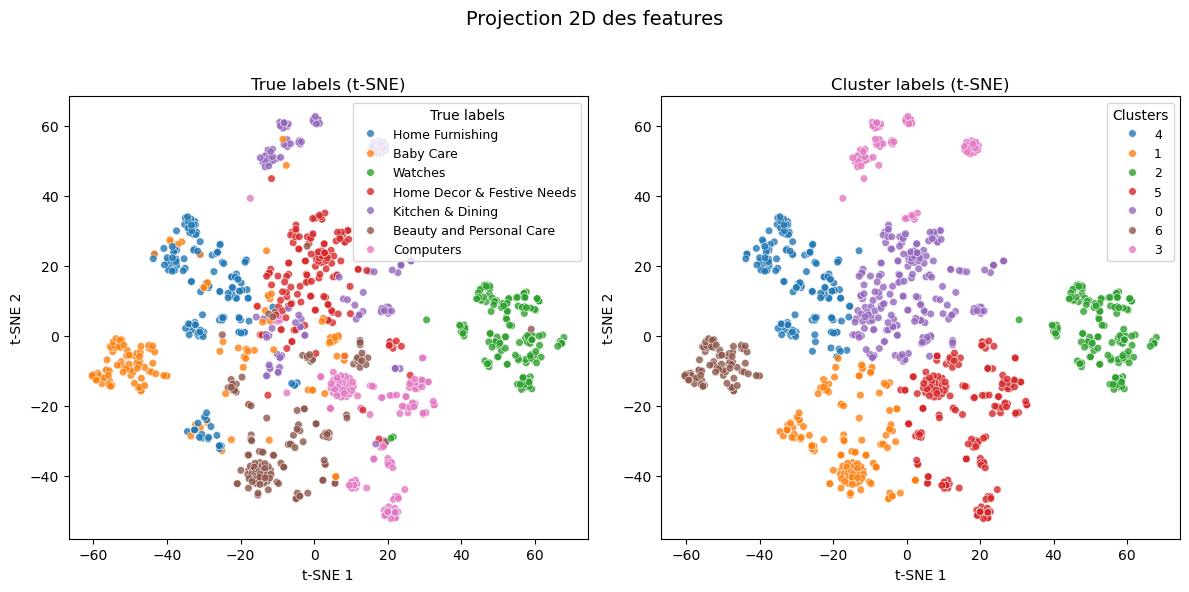

In [49]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_3,
                          lemm_or_stemm='stem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_4)
)

# Extraction du temps avant l'extraction de features
start = time.time()

# Paramétrage de la fonction d'extraction de features
vectorizer = TfidfVectorizer(max_features=500)

# Transformation des textes
features = vectorizer.fit_transform(desc_cleaned)
features_dense = features.toarray() 

# Calcul du temps d'extraction de features
duration_TFIDF = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)

# Réduction de la dimensionnalité des features
features_tnse = tsne.fit_transform(features_dense)

# Appel de la fonction d'évaluation 
ari_TFIDF = clustering_and_evaluation(features_tnse, Data_txt,
                                      "TF-IDF",
                                      n_clusters=7, 
                                      verbose=True, 
                                      title="TF IDF + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_TFIDF = pd.DataFrame({
    'approche': ['TFIDF'],
    'ari': [ari_TFIDF],
    "temps d'execution": [duration_TFIDF]
})

# Ajout des résulats de l'approche TF-IDF dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_TFIDF])

Les même observations peuvent être faites lorsque la méthode TD-IDF est utilisée. Là encore, on observe un bon regroupement des produits de la catégorie Watch. Pour les autres catégories, la majorité des produits se rassemble correctement, mais un chevauchement entre certaines classes persiste. Néanmoins, le score ARI plus élevé obtenu avec cette approche suggère une meilleure structuration des données et reflète une segmentation plus précise que celle obtenue avec la représentation Bag of Words

### Word2Vec

Word2Vec est une autre méthode d'extraction de feature. Cette approche repose sur le fait qu'un mot prend son sens à partir des mots qui l’entourent. Donc, si deux mots apparaissent souvent dans des contextes similaires, alors leur vecteurs Word2Vec seront proches dans l’espace vectoriel.  Cette approche permet de détecter des relation sémantiques. Deux emples sont fréquemment utilisés pour illustrer cela 
- le vecteur de **roi** - le vecteur de **homme** + le vecteur de **femme** correspondra approximativement au vecteur **reine**. 
- le vecteur de **Paris** - le vecteur de **France** + le vecteur de **Italie** correspondra approximativement au vecteur **Rome**. 

Les modèles sont entrainés  grâce à un petit réseau de neurones. Lors de l'entrainement, le réseau apprend à associer chaque mot à un vecteur de taille fixe basé sur son usage dans le corpus. Les modèles Word2Vec sont entrainés sur deux taches:
- la tache CBOW qui consiste à prédire un mot cible à partir de son contexte. Le modèle reçoit en entrée plusieurs mots entourant un mot manquant, et apprend à deviner ce mot central. 
- la tache Skip-gram, qui à l’inverse, prend un mot en entrée et tente de prédire les mots de son contexte. 

Ici on va commencer par utiliser deux modèles work2vec déjà entrainés. Un modèle entrainé directement sur les données du projet sera éventuellement mis en place dans un second temps afin de voir s'il est possible d'améliorer la séparation des produits après projection des features sur l'espace 2D ainsi que les scores ARI du clustering.

- Le modèle fasttext-wiki-news-subwords-300 est un modèle qui a été entrainé par facebook sur un corpus correspondant à wikipedia complété par un ensemble de texte issus de site d'actualités. La taille du vocabulaire de ce corpus s'élève à environs 1 million de mots. Chaque mot est représenté comme une somme de vecteurs de n grammes. Ce modèle gère donc très bien les mots inconnus grâce à la présence de ces sous mots. La dimension des vecteurs produits est de 300.

- Le modèle word2vec-google-news-300 est un modèle qui a été entrainé par google sur un corpus correspondant a des news google et comprend environs 100 milliard de mots. C'est un modèle Word2Vec classique de skip gram avec contexte. Il ne contient que des mots connus et ne peut donc pas gérer les cas de mots inconnus. La dimension des vecteurs produits est également de 300.


In [50]:
# Chargement du modèle fasttext si pas déjà présents en local
if not os.path.exists("../Models/Text_embedding/W2V/fasttext_wiki_news_300.model"):
    print("Téléchargement de fasttext-wiki-news-subwords-300...")
    w2v_model_1 = api.load("fasttext-wiki-news-subwords-300")
    w2v_model_1.save("../Models/Text_embedding/W2V/fasttext_wiki_news_300.model")
else:
    print("Modèle fasttext déjà présent localement.")
    w2v_model_1 = KeyedVectors.load("../Models/Text_embedding/W2V/fasttext_wiki_news_300.model", mmap='r')


# Chargement du modèle word2vec de google si pas déjà présents en local
if not os.path.exists("../Models/Text_embedding/W2V/word2vec_google_news_300.model"):
    print("Téléchargement de word2vec-google-news-300...")
    w2v_model_2 = api.load("word2vec-google-news-300")
    w2v_model_2.save("../Models/Text_embedding/W2V/word2vec_google_news_300.model")
else:
    print("Modèle word2vec déjà présent localement.")
    w2v_model_2 = KeyedVectors.load("../Models/Text_embedding/W2V/word2vec_google_news_300.model", mmap='r')

Modèle fasttext déjà présent localement.
Modèle word2vec déjà présent localement.


Pour obtenir des vecteurs pour chaque description, on va définir une fonction qui va séparer les mots de chaque descriptions en token en séparant simplement par espace. Ensuite on utilisera le modèle chargé pour récupérer pour chaque mot de chaque description les vecteurs W2V associés au mots lorsque ceux ci existent dans le vocabulaire du modèle. Le vecteur final associé à chaque description correspond à la moyenne de tous les vecteurs mots obtenus par le modèle Word2Vec.

In [51]:
def word2vec_embed(desc, w2v_model):
    """
    Transforme une liste de textes en vecteurs Word2Vec moyens.
    
    Paramètres:
        desc (list of str): Liste de documents (chaînes de caractères).
        w2v_model (gensim Word2Vec or KeyedVectors): Modèle Word2Vec pré-entraîné.
    
    Sortie:
        np.ndarray: Matrice (n_docs, dim) des vecteurs moyens.
    """
    
    # Extraction de la dimension du vecteur de sortie
    dim = w2v_model.vector_size
    
    # Initialisation de la liste de features
    features = []

    # Pour chaque description
    for doc in desc:
        
        # Découpage simple des mots par espace
        words = doc.split()  
        
        # Obtentien des vecteurs mots si le mot est présent dans le model w2v
        vecs = [w2v_model[w] for w in words if w in w2v_model]
        
        # Si le vecteur est non nul, le vecteur final correspond à la moyenne des vecteur mots
        if vecs:
            mean_vec = np.mean(vecs, axis=0)
            
        # Sinon le vecteur final est construit manuellement et correspond à un vecteur nul
        else:
            mean_vec = np.zeros(dim)
            
        # Ajout des vecteurs dans la liste de feature
        features.append(mean_vec)

    return np.array(features)


Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

===== W2V 1 + TSNE + KMeans===== 
ARI : 0.4945


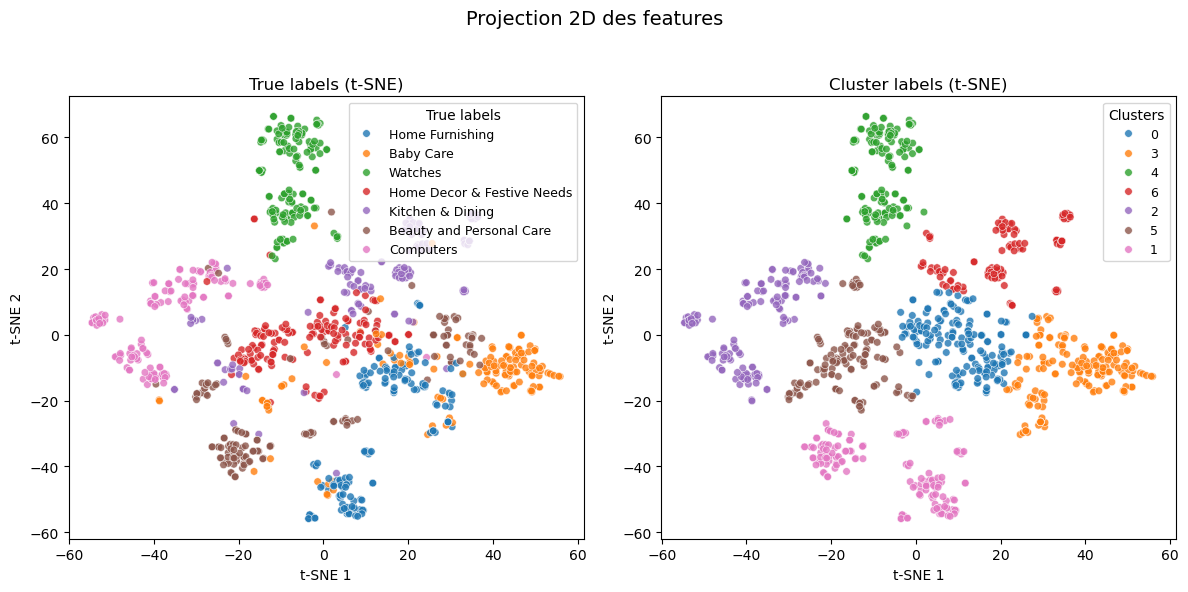

In [52]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_1,
                          lemm_or_stemm='stem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_4)
)
# Calcul du temps d'extraction de feature
start = time.time() 

# Vectorisation
features = word2vec_embed(desc_cleaned.tolist(), w2v_model_1)

# Calcul du temps d'extraction de feature
duration_W2V_1 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)

# Réduction de la dimensionnalité des features
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_W2V_1 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "Word_2_Vec modele1",
                    n_clusters=7, 
                    verbose=True, 
                    title="W2V 1 + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_W2V_1 = pd.DataFrame({
    'approche': ['W2V_1'],
    'ari': [ari_W2V_1],
    "temps d'execution": [duration_W2V_1]
})

# Ajout des résulats du modèle W2V dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_W2V_1])

Lorsque les features sont extraites grâce à un modèle Word2Vec déjà entrainé, on observe une amélioration de la séparation des produits en fonction de leur catégories malgrès un score ARI légèrement plus faible. Les produits de la catégorie Watch correspondent à nouveau aux produits qui se rassemblent le mieux. On remarque ici une meilleure séparation des produits de la catégorie computers. On a encore des chevauchement, en particulier entre les produits de la catégorie Home Decor et Kitchen and dining. Les produits de la catégorie baby care se regroupe globalement bien ensemble mais on retrouve des produits de cette catégorie mélangés à d'autres produits.

Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

===== W2V 2 + TSNE + KMeans===== 
ARI : 0.4003


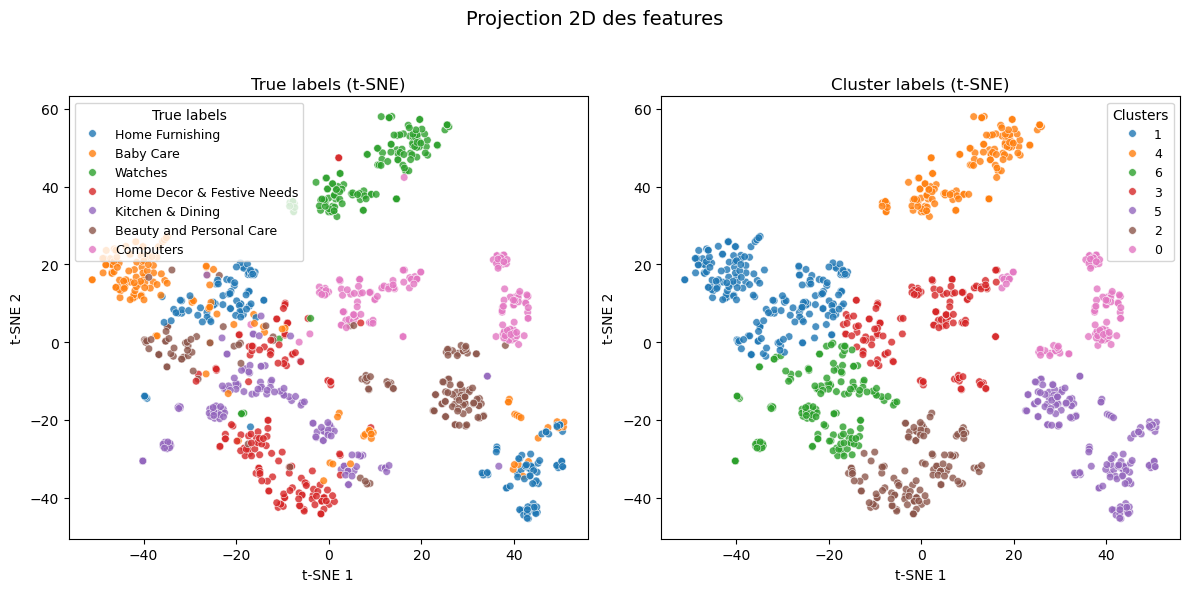

In [53]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_1,
                          lemm_or_stemm='stem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_7))

# Calcul du temps d'extraction de feature
start = time.time() 

# Vectorisation
features = word2vec_embed(desc_cleaned.tolist(), w2v_model_2)

# Calcul du temps d'extraction de feature
duration_W2V_2 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)

# Réduction de la dimensionnalité des features
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_W2V_2 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "Word_2_Vec modele2",               
                    n_clusters=7, 
                    verbose=True, 
                    title="W2V 2 + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_W2V_2 = pd.DataFrame({
    'approche': ['W2V_2'],
    'ari': [ari_W2V_2],
    "temps d'execution": [duration_W2V_2]
})

# Ajout des résulats du modèle W2V dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_W2V_2])

L'utilisation du deuxieme modèle W2V pré entrainé aboutit à des résultats similaires à ceux obtenus avec le premier modèle. Néanmoins on remarque pour la catégorie Home Furnishing que les produits se rassemblent dans deux groupes distinct plus  éloignés l'un de l'autre qu'il ne l'était avec le modèle précédent. En revanche, on retrouve les produits de la catégorie Watch et computer qui sont à nouveau bien séparés des produits des autres catégories. On peut essayer d'améliorer ces résultats en entrainant un modèle W2V sur nos propres données. 

### Entrainement d'un modèle word2vec sur les données 

Pour cette approche, on va commencer par entrainer un modèle W2V sur nos donnée. Pour cela on va utiliser la librairie gensim qui permet d'apprendre a représenter chaque mots sous la forme d'un vecteur basé sur son contexte. Plusieurs paramètres seront utilisés: vector_size (pour fixer la taille des vecteurs des mots appris), window (qui défini la taille du contexte a prendre en compte autour de chaque mots), min_cout (qui indique la fréquence minimal à considérer pour qu'un mot soit conservé) et epochs (qui indique le nombre de passage du modèle sur les données).

Les descriptions sont ensuite tokenisées en séquence d'indice numérique grâce à un Tokeniser de Keras. Chaque mot est alors remplacé par son identifiant unique. Les descriptions sont ensuite paddés à une longueur fixe définie par maxlen pour être compatible avec le modèle de Keras.

A partir du vocabulaire correspondant au tokeniser, on construit par la suite une matrice d'embedding où chaque ligne correspond à un mot du tokeniser. Si le mot est connu du modèle word2vec, son vecteur est ajouté, sinon la ligne correspondant au mot est rempli de 0. Cette matrice est utilisé comme poids dans la couche d'embedding. 

A la dernière étape on crée un modèle Keras qui sera composé d'une couche d'embedding initialisé avec la matrice d'embedding construite précédemment suivie d'une couche de pooling pour obtenir un vecteur fixe par phrase.

On peut ensuite utiliser ce modèle pour vectoriser de nouvelle description. 

In [54]:
def W2V_entrainement(descriptions, w2v_size, w2v_window, w2v_min_count, w2v_epochs):
    
    """
    Entraîne un modèle Word2Vec à partir d'une liste de descriptions textuelles.

    Paramètres:
        descriptions (list of str): Liste de phrases ou documents à vectoriser.
        w2v_size (int): Dimension des vecteurs de sortie.
        w2v_window (int): Taille de la fenêtre de contexte autour d’un mot.
        w2v_min_count (int): Seuil minimal de fréquence pour qu’un mot soit inclus dans le vocabulaire.
        w2v_epochs (int): Nombre d’époques d'entraînement du modèle Word2Vec.

    Sortie:
        model (gensim.models.Word2Vec): Modèle Word2Vec entraîné.
        prep_desc (list of list of str): Descriptions prétraitées (tokenisées en listes de mots).
    """
    
    # Application d'un preprocessing simple de la librairie gensim
    prep_desc = [simple_preprocess(text) for text in descriptions]
    
    # Initialisation du modèle Word2Vec
    print("Build & train Word2Vec model ...")
    model = Word2Vec(min_count=w2v_min_count, 
                         window=w2v_window,                     
                         vector_size=w2v_size,                         
                         seed=42,
                         workers=1)
    
    #  Construction du vocabulaire qui sera utilisé par le modèle                                              
    model.build_vocab(prep_desc)
    
    # Entrainement du modèle
    model.train(prep_desc, total_examples=model.corpus_count, epochs=w2v_epochs)
    
    # Exctraction des vecteurs mots construits par modèle
    model_vectors = model.wv
    
    # Extraction des mots du vocuabulaire appris par le modèle trié par fréquence décroissante
    w2v_words = model_vectors.index_to_key
    
    # Affichage de la taille du vocabulaire
    print("Vocabulary size: %i" % len(w2v_words))
    print("Word2Vec trained")
    
    return model, prep_desc

def prepare_tokeniser_et_sequence(descriptions, maxlen): 
    """
    Prépare les séquences de texte: tokenisation, transformation en indices et padding.

    Paramètres:
        descriptions (list of str): Liste de textes à transformer.
        maxlen (int): Longueur maximale des séquences après padding.

    Sortie:
        tokenizer (Tokenizer): Objet Keras Tokenizer entraîné.
        x_sentences (np.ndarray): Séquences d'indices de mots, padées à maxlen.
        word_index (dict): Dictionnaire des mots et de leurs indices.
    """
    
    # Préparation des phrases (tokenization + padding)
    print("Fit Tokenizer ...")
    
    # Initialisation du tokenizer
    tokenizer = Tokenizer()
    
    # Tokenisation pour obtenir un index numérique pour chaque mot
    tokenizer.fit_on_texts(descriptions)
    
    # Suppression de mots ou ajout de pad et transformation des phrases en séquences d'indices
    x_sentences = pad_sequences(tokenizer.texts_to_sequences(descriptions),
                                                         maxlen=maxlen,
                                                         padding='post') 
    # Calcul de la taille du vocabulaire
    word_index = tokenizer.word_index
    vocab_size = len(word_index) 
    print("Number of unique words: %i" % vocab_size)
    
    return tokenizer, x_sentences, word_index

def creation_matrice_embedding(word_index, model_vectors, w2v_size):
    """
    Crée une matrice d'embedding à partir d’un vocabulaire tokenisé et des vecteurs Word2Vec.

    Paramètres:
        word_index (dict): Dictionnaire {mot: index} du tokenizer.
        model_vectors (gensim.models.KeyedVectors): Vecteurs de mots entraînés via Word2Vec.
        w2v_size (int): Dimension des vecteurs de mots.

    Sortie:
        embedding_matrix (np.ndarray): Matrice d'embedding (vocab_size x w2v_size).
        vocab_size (int): Taille du vocabulaire.
    """
    
    # Création de la matrice d'embedding
    print("Create Embedding matrix ...")
    
    # Taille du vocabulaire
    vocab_size = len(word_index) + 1
    
    # Initialisation de la matrice d'embedding
    embedding_matrix = np.zeros((vocab_size, w2v_size))
    i=0
    j=0

    # Pour chaque mots et index du tokeniser
    for word, idx in word_index.items():
        i +=1
        
        # si le mot est dans le vocabulaire Word2Vec
        if word in model_vectors:
            j +=1
            
            # Extraction du vecteur du mot
            embedding_vector = model_vectors[word]
            
            # Si le vecteur existe
            if embedding_vector is not None:
                
                # Ajout du vecteur du mot dans la matrice
                embedding_matrix[idx] = model_vectors[word]

    # Calcul du ratio de mots avec un vecteur W2V par rapport au nombre de mots du tokeniser
    word_rate = np.round(j/i,4)
    
    # Affichage des résultats
    print("Word embedding rate : ", word_rate)
    print("Embedding matrix: %s" % str(embedding_matrix.shape))
    
    return embedding_matrix, vocab_size

def construction_model_embedding(vocab_size, w2v_size, embedding_matrix, maxlen):
    """
    Construit un modèle Keras d'embedding basé sur une moyenne des vecteurs Word2Vec.

    Paramètres:
        vocab_size (int): Taille du vocabulaire.
        w2v_size (int): Dimension des vecteurs de mots.
        embedding_matrix (np.ndarray): Matrice d’embedding (vocab_size x w2v_size).
        maxlen (int): Longueur maximale des séquences d’entrée.

    Sortie:
        embed_model (keras.Model): Modèle Keras produisant une représentation vectorielle d’un texte via la moyenne des embeddings.
    """
    
    # Définition de la couche d'entrée
    word_input=Input(shape=(maxlen,),dtype='float64') 
    
    # Définition de la couche d'embedding
    word_embedding=Embedding(input_dim=vocab_size,
                             output_dim=w2v_size,
                             weights = [embedding_matrix])(word_input)
    
    # Calcul de la moyenne des vecteurs sur la sequence entière
    word_vec=GlobalAveragePooling1D()(word_embedding)
    
    # Création du modèle
    embed_model = Model([word_input],word_vec)
    
    # Affichage des caractéristique du modèle
    embed_model.summary()
    
    return embed_model

In [55]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_1,
                          lemm_or_stemm='stem',
                          min_len_words=3,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_7)
)

# Définition des paramètres de la fonction d'entrainement
w2v_size=100
w2v_window=5
w2v_min_count=1
w2v_epochs=200
maxlen = 200

# Entrainement du modèle W2V
mon_model, prep_desc = W2V_entrainement(desc_cleaned.to_list(), 
                                        w2v_size=w2v_size, 
                                        w2v_window=w2v_window,
                                        w2v_min_count=w2v_min_count,
                                        w2v_epochs=w2v_epochs)

# Préparation des descritions pour l'entrainement
tokenizer, x_sentences, word_index = prepare_tokeniser_et_sequence(prep_desc, maxlen=maxlen)

# Consttruction de la matrice d'embedding
embedding_matrix, vocab_size = creation_matrice_embedding(word_index, mon_model.wv, w2v_size)

# Construction du modèle d'embedding
embed_model = construction_model_embedding(vocab_size,  w2v_size, embedding_matrix, maxlen)


Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

Build & train Word2Vec model ...
Vocabulary size: 3367
Word2Vec trained
Fit Tokenizer ...
Number of unique words: 3367
Create Embedding matrix ...
Word embedding rate :  1.0
Embedding matrix: (3368, 100)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 200, 100)            │         336,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 100)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 336,800 (1.28 MB)

 Trainable params: 336,800 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
===== W2V trained + TSNE + KMeans===== 
ARI : 0.4627


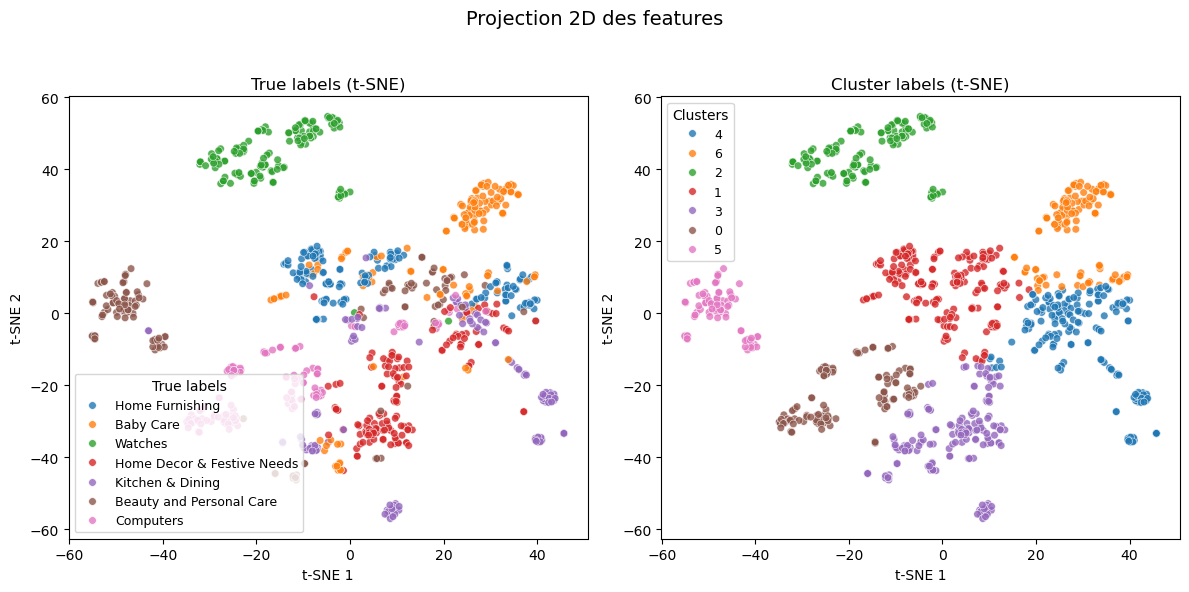

In [56]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, stop_words, rejoin=True,
                          list_of_rare_words=low_frequency_words_3,
                          lemm_or_stemm='lem',
                          min_len_words=2,
                          force_is_alpha=True,
                          eng_words=None,
                          common_words=mots_communs_7))

# Pretaitement appliqué pour la construction du modèle
processed = [simple_preprocess(text) for text in desc_cleaned.to_list()]

# Conversion des descriptions en séquence d'indices avec le tokenizer 
sequences = tokenizer.texts_to_sequences(processed)

# Application du padding
sequences_padded = pad_sequences(sequences, maxlen=200, padding='post')

# Calcul du temps d'extraction de feature
start = time.time() 

# Utilisation du modyèle d'embedding entrainé
features = embed_model.predict(sequences_padded)

# Calcul du temps d'extraction de feature
duration_W2V_trained = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)

# Réduction de la dimensionnalité des features
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_W2V_trained = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "Word_2_Vec trained",
                    n_clusters=7, 
                    verbose=True, 
                    title="W2V trained + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_W2V_trained = pd.DataFrame({
    'approche': ['W2V_trained'],
    'ari': [ari_W2V_trained],
    "temps d'execution": [duration_W2V_trained]
})

# Ajout des résulats du modèle W2V dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_W2V_trained])

L'entrainement d'un modèle W2V sur nos propres données permet d'obtenir une amélioration visuelle de la séparation de certains produits. Alors qu'auparavant, on retrouvait quelques produits n'appartenant pas à la catégorie Watch dans le groupe de produits correspondant à cette catégorie, ici, aucun intrus n'est retrouvé parmis les produits de la catégorie watch. Les produits de la catégorie Beauty and Personnal care apparaissent mieux séparé avec les features extraites par ce modèle comparés au deux autres modèles W2V pré entrainés même si quelques prodruits se retrouvent à nouveau mélangés à d'autres catégories. En revanche les produits de la catégorie computers semblent se regrouper moins bien que prédédemment.

### BERT

Les modèles BERT (Bidirectional Encoder Representations from Transformers) sont des modèles de NLP qui ont profondément transformé la compréhension automatique du texte en permettant aux modèles de mieux saisir le contexte des mots dans une phrase. Contrairement aux modèles classiques qui lisent le texte de manière unidirectionnelle (de gauche à droite ou de droite à gauche), BERT est bidirectionnel. Cela signifie qu’il prend en compte simultanément les mots à gauche et à droite d’un mot pour en comprendre le sens exact dans la phrase, ce qui améliore considérablement la qualité des résultats d'un point de vue compréhension de la sémentique d'une phrase. Alors que W2V produits un vecteur unique par mot, BERT va produire un vecteur par mot et par context.

Cette capacité est rendue possible grâce à l’utilisation d’un type d'architecture de réseau de neurones, appelée Transformer. Toutefois à la différence d'autres approches, BERT utilise uniquement la partie "encodeur" de cette architecture qui consiste à lire l’ensemble de la séquence d’entrée et à produire une représentation contextuelle riche de chaque mot, en tenant compte de son environnement. Le cœur du Transformer repose sur un mécanisme appelé attention, qui permet au modèle de pondérer l’importance des autres mots dans la séquence pour chaque mot donné.

BERT est d'abord entraîné sur un corpus massif comme Wikipedia sans tâche précise, en apprenant deux objectifs :
- La prédiction de mots masqués : certains mots sont cachés dans une phrase, et le modèle doit deviner ces mots.
- La prédiction de la relation entre deux phrases : BERT apprend si une phrase suit logiquement une autre.

Ce pré-entraînement génère un modèle que l’on peut ensuite adapter à une tâche spécifique en ajoutant simplement une couche finale adaptée et en réalisant un fine-tuning sur un jeu de données plus petit spécifique de la tâche à réaliser.

Deux modèles seront analysés dans le cadre de ce projet:
- le modèle bert uncased  de la librairie Hugging Face 
- le modèle bert uncased de la librairie TensorFlow Hub

Il s'agit en réalité de modèles qui font la même chose mais qui ont été implémenté de façon différentes. Le modèle BERT uncased a été développé par Google. Le terme uncased signifie que lors du prétraitement des textes, toutes les lettres ont été converties en minuscules et que les marques de ponctuation ont été supprimées. Le modèle uncased est particulièrement adapté aux cas où la casse n’apporte pas d’information importante, comme dans les tâches de classification de certain textes générale.

In [57]:
# Suppression de certains warnings
get_logger().setLevel('ERROR')

# Chargement du modèle HF classique (bert-base-uncased) si absent
if not os.path.exists('../Models/Text_embedding/hf_bert-base-uncased'):
    print("Téléchargement du modèle HF bert-base-uncased...")
    tokenizer_model_1 = AutoTokenizer.from_pretrained('bert-base-uncased')
    bert_model_1 = TFAutoModel.from_pretrained('bert-base-uncased')
    tokenizer_model_1.save_pretrained('../Models/Text_embedding/hf_bert-base-uncased')
    bert_model_1.save_pretrained('../Models/Text_embedding/hf_bert-base-uncased')
else:
    print("Modèle HF bert-base-uncased déjà présent localement.")
    tokenizer_model_1 = AutoTokenizer.from_pretrained('../Models/Text_embedding/hf_bert-base-uncased')
    bert_model_1 = TFAutoModel.from_pretrained('../Models/Text_embedding/hf_bert-base-uncased')

# Chargement du modèle TF classique (bert-base-uncased)
bert_model_2 = hub.KerasLayer('https://tfhub.dev/tensorflow/bert_en_uncased_L-12_H-768_A-12/4', trainable=True)
tokenizer_model_2 = AutoTokenizer.from_pretrained('bert-base-uncased') 


Modèle HF bert-base-uncased déjà présent localement.


TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFBertModel.

All the layers of TFBertModel were initialized from the model checkpoint at ../Models/Text_embedding/hf_bert-base-uncased.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions without further training.


La fonction associée à la méthode BERT sera un peu plus complexe. Ici on utilisera les modèles préentrainés chargés précédemment. Pour gagner en temps de calcul, le code s'effectura en batch.

Dans une première étape les descriptions sont préparées pour obtenir 3 objets de type tenseurs 2D (liste de vecteur) attendus par le modèle BERT (inputs_ids, token_type_ids, attention_mask). Pour chaque description, l'utilisation d'un tokenizer préchargé permettra d'ajouter des tokens spéciaux dont les tokens CLS et SEP. Le token CLS est ajouté au début de chaque séquences. Les descriptions seront éventuellement tronquées ou remplies pour atteindre une longueur fixe définie par un paramètre d'entrée. Cela permettra d'obtenir les inputs ids, les masque d'attention et les token type ids qui sortent dans un objet de type tenseur comportant les trois vecteurs.

L'étape suivante consistera a extraire des vecteurs de caractéristiques pour chaque description. Deux modes seront codés : le mode hugginface (HF) et le mode TensorFlow Hub (TFHub) qui seront utilisés en fonction du type de modèle qui sera utilisé. 
- Pour le mode HF on passe au modèle les arguments inputs-ids, attention mask et token_type_id puis on récupère une sortie sous forme de tenser 3D de dimension ([batch_size, max_length, hidden_size] -> chaque token est représenté par un vecteur de dimension hidden_size correspondant à dernière couche du modèle. 
- Pour le mode TFhub on prépare un dictionnaire avant de le passer au modèle puis on récupère à la sortie le tenseur contenu dans la clé sequence_output

Les sorties pour tous les batchs sont rassemblées dans une liste, puis converties en tableaux NumPy.

Une dernière étape de pooling permettra d'obtenir un vecteur unique par description. Plusieurs approches peuvent être utilisées. L'une d'entre elles consiste à effectuer une moyenne sur tous les tokens (sauf les tokens PAD: token ajoutés pour compléter la longueur d'une description). La deuxieme consiste à extraire le vecteur du token CLS correspondant au premier token qui capture le sens global de la séquence.

En plus des paramètres liés au prétraitement des descriptions et à la réduction de dimensionalité, on pourra tester différentes valeurs de taille maximum des séquences à fournir au modèle, et différentes méthodes de pooling.

In [58]:
def bert_embed(desc, tokenizer, model, mode='HF', max_length=64, batch_size=16, pooling='mean'):
    """
    Extrait des embeddings BERT à partir d'une liste de textes.

    Paramètres:
        desc (list of str): Textes à encoder.
        tokenizer: Tokenizer BERT (HuggingFace ou compatible TFHub).
        model: Modèle BERT (HuggingFace ou TFHub).
        mode (str): 'HF' (HuggingFace) ou 'TFhub'.
        max_length (int): Longueur maximale de séquence.
        batch_size (int): Taille des batchs.
        pooling (str): 'mean' ou 'cls'.

    Sortie:
        np.ndarray: Matrice (n_docs, dim) d'embeddings.
    """
    
    # Initialisation des résultats
    all_hidden_states = []

    # Pour chaque batch
    for i in range(0, len(desc), batch_size):
        
        # Extraction des description du batch
        batch_desc = desc[i:i+batch_size]
        
        # Initialisation des tenseurs d'entrée
        input_ids, token_type_ids, attention_mask = [], [], []
        
        # Pour chaque description
        for sent in batch_desc:
            
            # Tokenisation
            encoded = tokenizer.encode_plus(
                sent,
                add_special_tokens=True,
                max_length=max_length,
                padding='max_length',
                truncation=True,
                return_attention_mask=True,
                return_token_type_ids=True,
                return_tensors='tf'
            )
            
            # Ajout des tenseurs dans la liste de tenseurs d'entrée
            input_ids.append(encoded['input_ids'][0])
            token_type_ids.append(encoded['token_type_ids'][0])
            attention_mask.append(encoded['attention_mask'][0])

        # Empilement des differentes tenseurs pour créer un tenseur unique pour chacune des trois entrées
        input_ids = stack(input_ids)
        token_type_ids = stack(token_type_ids)
        attention_mask = stack(attention_mask)

        # Si le modèle est de type hg
        if mode == 'HF':
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            hidden_states = outputs.last_hidden_state

        elif mode == 'TFhub':
            inputs = {
                'input_word_ids': input_ids,
                'input_mask': attention_mask,
                'input_type_ids': token_type_ids
            }
            outputs = model(inputs)
            hidden_states = outputs['sequence_output']

        all_hidden_states.append(hidden_states.numpy())

    all_hidden_states = np.concatenate(all_hidden_states, axis=0)

    # Pooling
    if pooling == 'mean':
        features = all_hidden_states.mean(axis=1)
    elif pooling == 'cls':
        features = all_hidden_states[:, 0, :]
    else:
        raise ValueError("Pooling must be 'mean' or 'cls'.")

    return features


In [59]:
def bert_embedding(desc, tokenizer, model, mode='HF', max_length=64, batch_size=16, pooling='mean'):
    """
    Extrait des embeddings BERT à partir d'une liste de textes.

    Paramètres:
        desc (list of str): Textes à encoder.
        tokenizer: Tokenizer BERT (HuggingFace ou compatible TFHub).
        model: Modèle BERT (HuggingFace ou TFHub).
        mode (str): 'HF' (HuggingFace) ou 'TFhub'.
        max_length (int): Longueur maximale de séquence.
        batch_size (int): Taille des batchs.
        pooling (str): 'mean' ou 'cls'.

    Sortie:
        np.ndarray: Matrice (n_docs, dim) d'embeddings.
    """
    
    # Initialisation des résultats
    all_hidden_states = []

    # Pour chaque batch
    for i in range(0, len(desc), batch_size):
        
        # Extraction des description du batch
        batch_desc = desc[i:i+batch_size]
        
        # Initialisation des tenseurs d'entrée
        input_ids, token_type_ids, attention_mask = [], [], []
        
        # Pour chaque description
        for sent in batch_desc:
            
            # Tokenisation
            encoded = tokenizer.encode_plus(
                sent,
                add_special_tokens=True,
                max_length=max_length,
                padding='max_length',
                truncation=True,
                return_attention_mask=True,
                return_token_type_ids=True,
                return_tensors='tf'
            )
            
            # Ajout des tenseurs dans la liste de tenseurs d'entrée
            input_ids.append(encoded['input_ids'][0])
            token_type_ids.append(encoded['token_type_ids'][0])
            attention_mask.append(encoded['attention_mask'][0])

        # Empilement des differentes tenseurs pour créer un tenseur unique pour chacune des trois entrées
        input_ids = stack(input_ids)
        token_type_ids = stack(token_type_ids)
        attention_mask = stack(attention_mask)

        # Si le modèle est de type HF
        if mode == 'HF':
            
            # Execution du modèle
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            # Extraction des vecteurs de sortie
            last_hidden_states = outputs.last_hidden_state

        # Si le modèle est de type TFHub
        elif mode == 'TFhub':
            
            # Conversion des entrées en format dictionnaire
            inputs = {
                'input_word_ids': input_ids,
                'input_mask': attention_mask,
                'input_type_ids': token_type_ids
            }
            
            # Execution du modèle
            outputs = model(inputs)
            
            # Extraction de la sortie
            last_hidden_states = outputs['sequence_output']
            
        # Ajout de la sortie dans la liste de résultats   
        all_hidden_states.append(last_hidden_states.numpy())

    # Fusion
    all_hidden_states = np.concatenate(all_hidden_states, axis=0)

    # Pooling
    if pooling == 'mean':
        features = all_hidden_states.mean(axis=1)
    elif pooling == 'cls':
        features = all_hidden_states[:, 0, :]


    return features


Pandas Apply:   0%|          | 0/1050 [00:00<?, ?it/s]

===== BERT 1 + TSNE + KMeans===== 
ARI : 0.3869


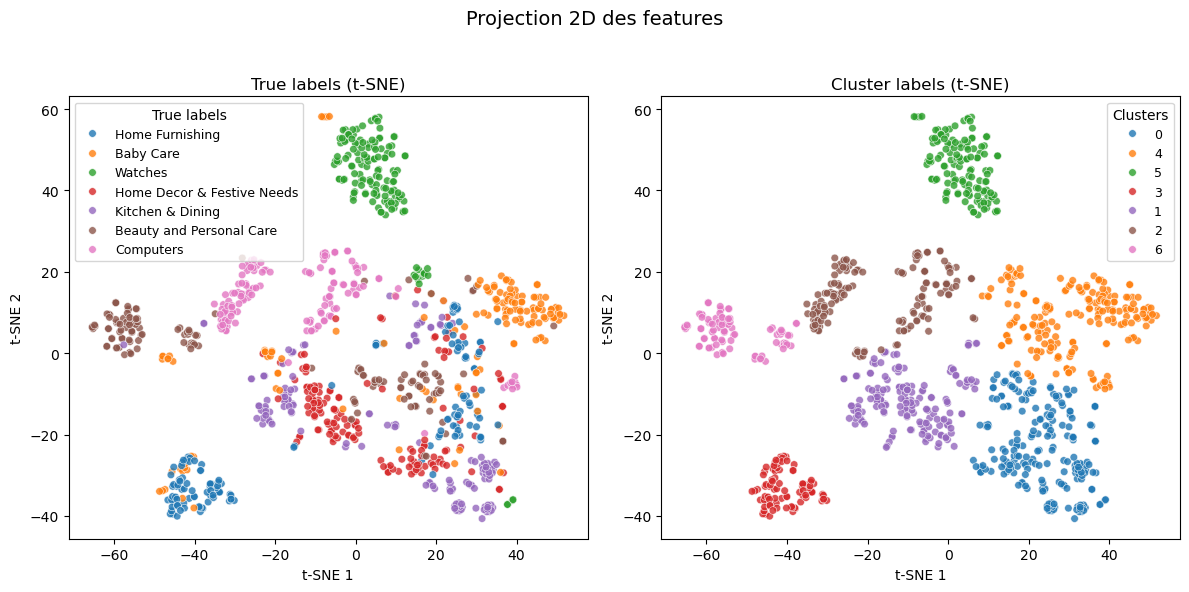

In [60]:
# Paramétrage de la fonction de prétraitement des descriptions
desc_cleaned = Data_txt.description.swifter.apply(
    lambda x: process_text(x, None, rejoin=True,
                          list_of_rare_words=None,
                          lemm_or_stemm=None,
                          min_len_words=None,
                          force_is_alpha=None,
                          eng_words=None,
                          common_words=None))

# Calcul du temps d'extraction de feature
start = time.time() 

# Transformation des textes
features = bert_embedding(desc_cleaned, tokenizer_model_1, bert_model_1)

# Calcul du temps d'extraction de feature
duration_BERT_1 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_BERT_1 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "BERT modele1",
                    n_clusters=7, 
                    verbose=True, 
                    title="BERT 1 + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_BERT_1 = pd.DataFrame({
    'approche': ['BERT_1'],
    'ari': [ari_BERT_1],
    "temps d'execution": [duration_BERT_1]
})

# Ajout des résulats du modèle USE dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_BERT_1])

Lorsque les features sont extraites grâce au premier modèle BERT pré entrainé, on remarque que les produits de la catégorie Watch se regoupent encore une fois globalement mieux que les produits des autres catégories. On peut aussi noter que la majorité des produits Beauty and Personal care et ceux de la catégorie Baby care apparaissent réunis à proximité les uns des autres bien que certains d'entre eux restent encore mélangés avec d'autres catégories. En revanche, les produits de la catégorie Kitchen and dining ont plus de mal à se rassembler.

===== BERT 2 + TSNE + KMeans===== 
ARI : 0.3860


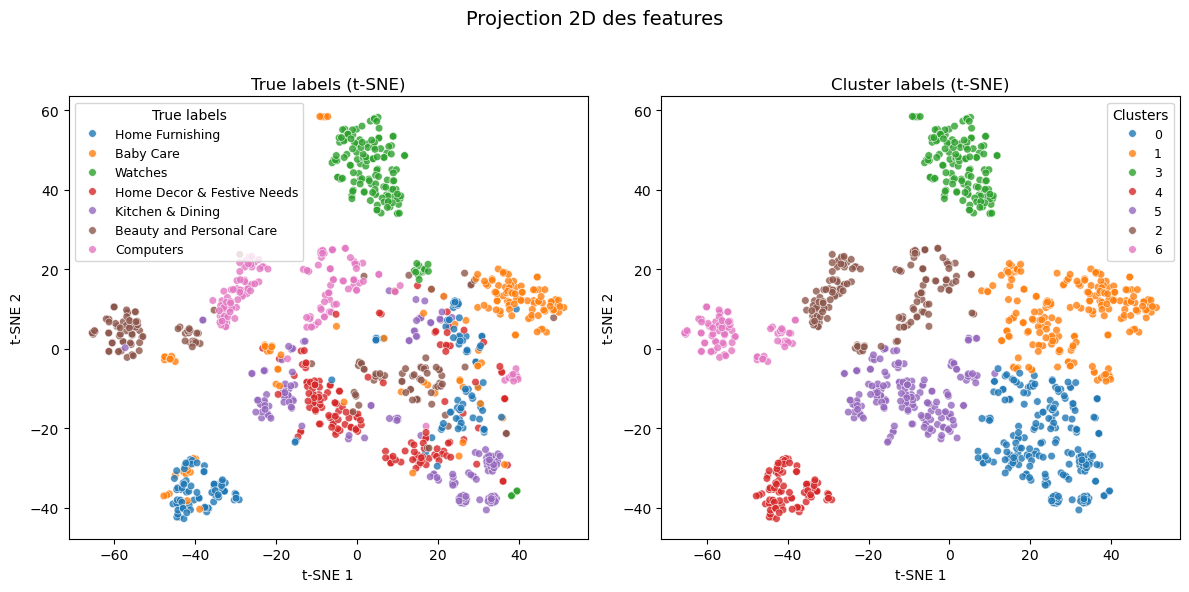

In [61]:
# Calcul du temps d'extraction de feature
start = time.time() 

# Transformation des textes
features = bert_embedding(desc_cleaned, tokenizer_model_2, bert_model_2, mode='TFhub')

# Calcul du temps d'extraction de feature
duration_BERT_2 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_BERT_2 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "BERT modele2",  
                    n_clusters=7, 
                    verbose=True, 
                    title="BERT 2 + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_BERT_2 = pd.DataFrame({
    'approche': ['BERT_2'],
    'ari': [ari_BERT_2],
    "temps d'execution": [duration_BERT_2]
})

# Ajout des résulats du modèle USE dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_BERT_2])

Lorsque les features sont extraites grâce au modèle BERT pré entrainé implémenté avec tensorflow hub, on retrouve la même structuration des données sur l'espace bidimensiennels à savoir: un bon regroupement des produits Watch, un regroupement mitigé pour les produits de Beauty and Personal Care et Baby Care, et un regroupement faible pour les produits de la catégorie Kitchen and Dining. On remarque également que les scores ARI sont identiques pour les deux modes d'implémentation ce qui indique que, malgré des différences dans les pipelines sous jacents, le modèle génère les même word embeddings. Cela suggère que la représentation vectorielle produite par BERT est stable et indépendante du cadre technique utilisé, tant que le modèle préentraîné reste le même.

###  Sentence Transformer

Les encodeurs de la librairie Sentence Transformer reposent également sur des architectures Transformer qui sont basées sur un mécanisme d'attention qui permet au modèle de mesurer l’importance relative de chaque mot dans une phrase, indépendamment de sa position. Ils ont été dérivés des modèles BERT et sont donc également capable de lire les phrases dans les deux sens. Ils ont été optimisé pour encoder des phrases entières notament grâce à un fine tuning sur la similarité sémentique où des paires de phrases similaires ou différentes sont utilisées pour entraîner le modèle. Cela les rend particulièrement précis pour capturer le sens global d’un texte et mesurer la proximité sémantique entre deux textes.

Deux modèles seront utilisés dans le cadre de ce projet: all MiniLM L6 V2 et all mpnet base v2.

- All-MiniLM-L6-v2 est un modèle léger et optimisé de la famille des Sentence Transformers, conçu pour générer rapidement des représentations vectorielles de phrases tout en conservant de bonnes performances. Il est basé sur MiniLM, qui correspond à une version distillée et plus compacte de BERT. Ce modèle a été fine tuné sur une large gamme de jeux de données pour des tâches de similarité et de recherche sémantique. Sa légèreté et sa rapidité en font un excellent compromis entre précision et efficacité computationnelle.

- MPNet (Masked and Permuted Pre-trained Network) est un modèle développé par Microsoft, qui combine les avantages de BERT et XLNet. Il utilise une stratégie de pré-entraînement, appelée permuted language modeling avec masquage, qui permet de mieux capturer les dépendances entre les mots tout en gardant une efficacité d'entraînement élevée.

In [62]:
# Téléchargement et sauvegarde du premier modèle
if not os.path.exists('../Models/Text_embedding/all-MiniLM-L6-v2'):
    print("Téléchargement de all-MiniLM-L6-v2...")
    transf_model_1 = SentenceTransformer('all-MiniLM-L6-v2')
    transf_model_1.save_pretrained('../Models/Text_embedding/all-MiniLM-L6-v2')
else:
    print("Modèle AllMiniLM déjà présent localement.")
    transf_model_1 = SentenceTransformer('../Models/Text_embedding/all-MiniLM-L6-v2')


# Téléchargement et sauvegarde du deuxiem modèle
if not os.path.exists('../Models/Text_embedding/all-mpnet-base-v2'):
    print("Téléchargement de all-mpnet-base-v2...")
    transf_model_2 = SentenceTransformer('all-mpnet-base-v2')    
    transf_model_2.save_pretrained('../Models/Text_embedding/all-mpnet-base-v2')
else:
    print("Modèle MPNET déjà présent localement.")
    transf_model_2 = SentenceTransformer('../Models/Text_embedding/all-mpnet-base-v2')



Modèle AllMiniLM déjà présent localement.
Modèle MPNET déjà présent localement.


Ici la fonction correspondant aux encodeurs de la librairie Sentence transformer sera plus simple car les modèles de cette librairie encapsule tout le processing (tokenisation, padding, troncation). Ces encodeurs gèrent aussi bien les batch que les étapes de pooling en interne et retourne un embedding numpy déjà prêt à l'emploi. En partculier, les deux modèles utilisés ici, le all mpnet-base-v2 ainsi que le all-MiniLM-L6-v2 utilise une approche de mean pooling pour obtenir les vecteurs finaux. 

In [63]:
def transformer_embed(desc, transf_model, batch_size=32):
    """
    Applique un modèle de type sentence-transformers pour encoder une liste de textes.

    Paramètres:
        texts (list of str): Textes à encoder.
        transf_model: Modèle sentence-transformers (ex: from SentenceTransformer).
        batch_size (int): Taille des batchs.

    Sortie:
        np.ndarray: Embeddings (n_docs, dim) sous forme de tableau numpy.
    """
    return transf_model.encode(
        desc,
        show_progress_bar=False,
        convert_to_numpy=True,
        batch_size=batch_size
    )


===== ST + TSNE + KMeans===== 
ARI : 0.5935


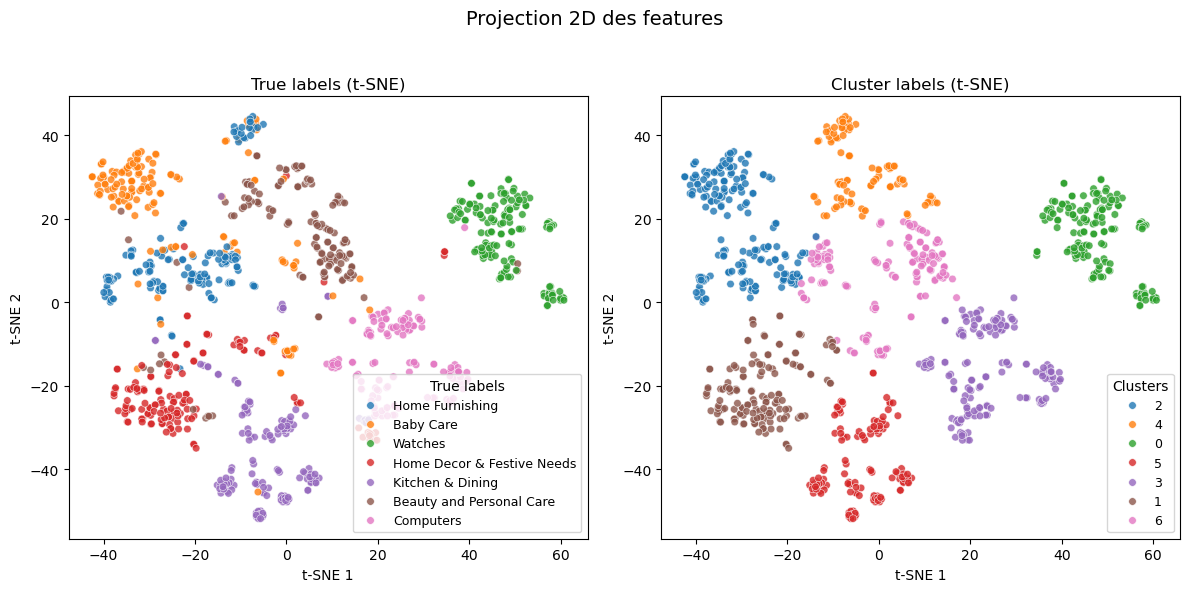

In [64]:
# Calcul du temps d'extraction de feature
start = time.time() 

# Transformation des textes
features = transformer_embed(Data_txt['description'].tolist(), transf_model_1)

# Calcul du temps d'extraction de feature
duration_ST_1 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)
features_tnse = tsne.fit_transform(features)


# Appel de la fonction d'évaluation 
ari_ST_1 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "all-MiniLM-L6",
                    n_clusters=7, 
                    verbose=True, 
                    title="ST + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_ST_1 = pd.DataFrame({
    'approche': ['ST_1'],
    'ari': [ari_ST_1],
    "temps d'execution": [duration_ST_1]
})

# Ajout des résulats du modèle USE dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_ST_1])

Lorsque les features sont extraites avec le premier modèle de Sentence transformer, les produits apparaissent moins mélangés entre les différentes catégories. On retrouve à nouveau que les produits de la catégorie Watch se rassemblent bien ensemble malgré la présence de quelques éléments issus d'autres catégories mêlés à ce groupe. Les produits de la catégorie Kitchen and dining et ceux de la catégorie Computer présente également un bon regroupement global. De plus, même si certains produits de la catégorie Home Decor se retrouvent encore un peu mélangé à d'autres produits, leur séparation apparaible plus nette avec cette approche.

===== ST + TSNE + KMeans===== 
ARI : 0.6666


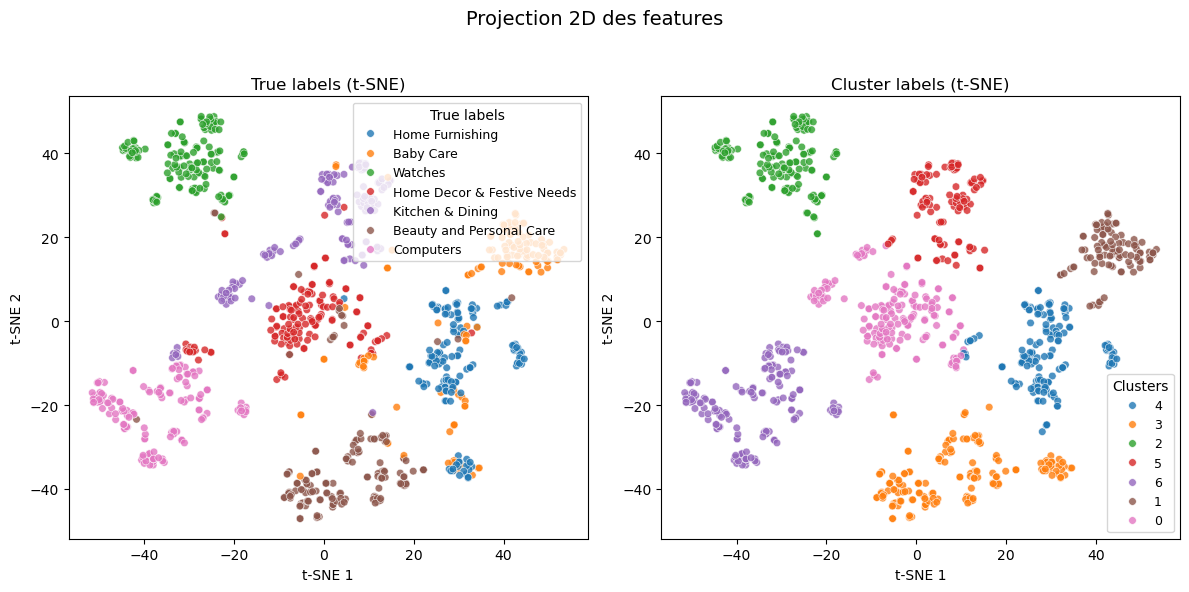

In [65]:
# Calcul du temps d'extraction de feature
start = time.time() 

# Transformation des textes
features = transformer_embed(Data_txt['description'].tolist(), transf_model_2)

# Calcul du temps d'extraction de feature
duration_ST_2 = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)
features_tnse = tsne.fit_transform(features)

# Appel de la fonction d'évaluation 
ari_ST_2 = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "all-mpnet-base-v2",
                    n_clusters=7, 
                    verbose=True, 
                    title="ST + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_ST_2 = pd.DataFrame({
    'approche': ['ST_2'],
    'ari': [ari_ST_2],
    "temps d'execution": [duration_ST_2]
})

# Ajout des résulats du modèle USE dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_ST_2])

La projection des features extraites avec le deuxième modèle pré entraîné de la librairie Sentence Transformer a également permis d’obtenir une très bonne séparation visuelle des produits selon leur catégorie. On constate en effet une réduction marquée des chevauchements entre les groupes, ce qui traduit une meilleure discrimination des catégories et une représentation plus claire des similarités entre produits appartenant à une même classe. Il s'agit pour le moment de l'approche qui a abouti à la meilleure séparation des produits selon leur catégorie.

### Use

USE est un outil d'encodage développé par Google pour transformer des phrases, des paragraphes ou même de courts textes en vecteurs numériques de taille fixe et compréhensibles par une machine. Ces vecteurs denses permettent aux modèles de comprendre le sens global du texte. Il en résulte que des phrases proches sémantiquement sont représentées par des vecteurs voisins, tandis que des phrases très différentes sont éloignées dans l’espace vectoriel. 

Le modèle USE repose sur des réseaux de neurones profonds et existe en plusieurs variantes dont s'appuie également sur une architecture de type transformer. Cela permet au modèle de capturer des relations complexe entre les mots meme sur de longue distance dans la phrase. Ces modèles ont été entrainés sur trois tâches:
- La prédiction de similarité entre des phrases
- L'apprentissage de relation sémantique fine comme la contraction, la cause à effet, ou la neutralité
- La modélisation de la continuité contextuelle entre deux phrases successives.

Les encodeurs USE sont des encodeurs clés en main ce qui signifie qu'il n'y a pas besoin de fine tuning sur de nouvelles données. La sortie est un vecteur par phrase de taille fixe qui a en général 512 dimensions. 

Dans ce projet, on utilisera la version 4 de l'universal sentence encoder (USE v4) qui est un modèle développé par Google pour générer des embeddings de phrases riches en informations sémantiques. Contrairement à BERT, qui se concentre sur le traitement token par token, USE encode directement des phrases ou des paragraphes en vecteurs de taille fixe, optimisés pour mesurer la similarité sémantique entre les textes.

In [66]:
# Chargement de l'encodeur USE
use_encoder_1 = hub.load('https://tfhub.dev/google/universal-sentence-encoder/4')

Les modèles de type USE englobe également une bonne partie des étapes comme la tokenisation, le pooling et le format des vecteurs de sortie. A la différence des encodeurs de la librairie Sentence Transformer, ils ne gèrent pas le batch en interne et il sera donc nécessaire de le coder manuellement. 

In [67]:
def use_embed(desc, use_model, batch_size=32, verbose=False):
    """
    Applique le modèle USE pour encoder une liste de textes.

    Paramètres:
        desc (list of str): Textes à encoder.
        use_model (tfhub model): Modèle Universal Sentence Encoder.
        batch_size (int): Taille des batchs.
        verbose (bool): Affichage ou non de la progression.

    Sortie:
        np.ndarray: Embeddings (n_docs, dim) sous forme de tableau numpy.
    """
    
    # Initialisation de la liste de feature
    features = []
    
    # Pour chaque batch
    for i in range(0, len(desc), batch_size):
        
        # Extraction des description du batch
        batch_desc = desc[i:i+batch_size]

        # Si demandé, affichage du batch en cours d'encodage
        if verbose:
            print(f"Encoding batch {step + 1}/{steps}...")

        # Execution du modèle 
        feat = use_model(batch_desc).numpy()

        # Ajout des features 
        features.append(feat)
        
    # Conversion en tableau numpy
    features  = np.vstack(features)

    return features


===== USE + TSNE + KMeans===== 
ARI : 0.4459


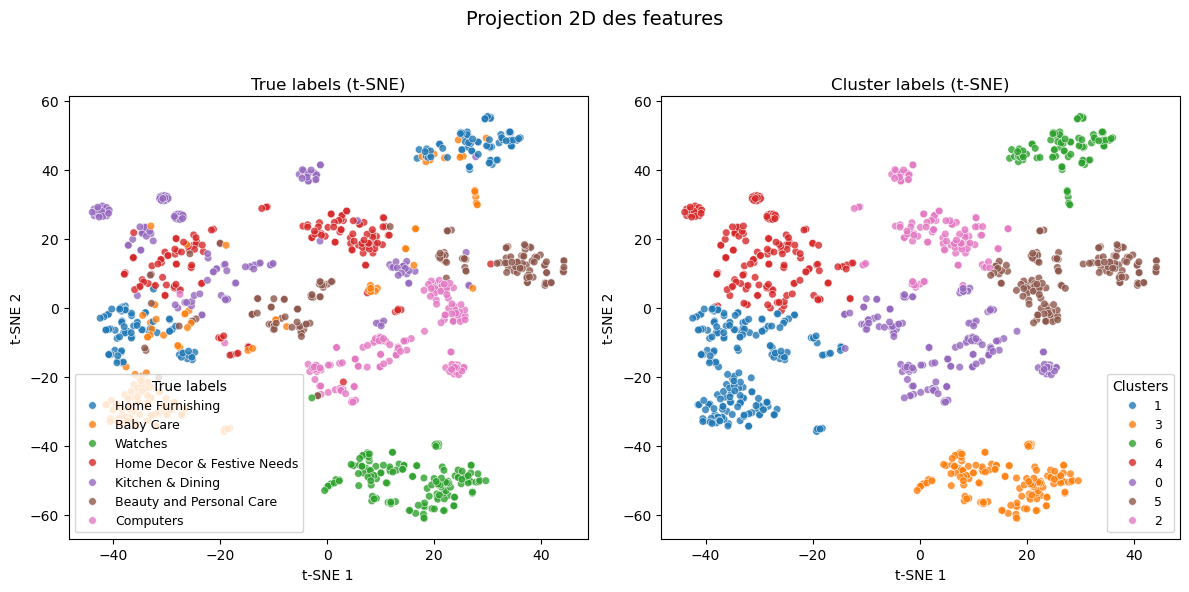

In [68]:
# Calcul du temps d'extraction de feature
start = time.time() 

# Transformation des textes
features = use_embed(Data_txt['description'].tolist(), use_encoder_1)

# Calcul du temps d'extraction de feature
duration_USE = time.time() - start

# Paramétrage de la fonction de réduction de dimension
tsne = TSNE(n_components=2, perplexity=20)
features_tnse = tsne.fit_transform(features)


# Appel de la fonction d'évaluation 
ari_USE = clustering_and_evaluation(features_tnse, 
                    Data_txt, 
                    "USE_v4",
                    n_clusters=7, 
                    verbose=True, 
                    title="USE + TSNE + KMeans")

# Création de la dataframe de résultats
Resultats_USE = pd.DataFrame({
    'approche': ['USE'],
    'ari': [ari_USE],
    "temps d'execution": [duration_USE]
})

# Ajout des résulats du modèle USE dans la dataframe contenant tous les résultats 
Resultats = pd.concat([Resultats, Resultats_USE])

Lorsque les features sont extraites avec l'encodeur USE, les produits apparaissent également mieux séparé qu'avec les modèles de BERT et que l'approche de BoW. Toutefois on observe un chevauchement plus important entre certaines catégories notamment entre les produits de la catégorie Home Decor et ceux de la catégorie Kitchen and dining care qu'avec le modèle de la librairie Sentence Transformer.

## Synthèse

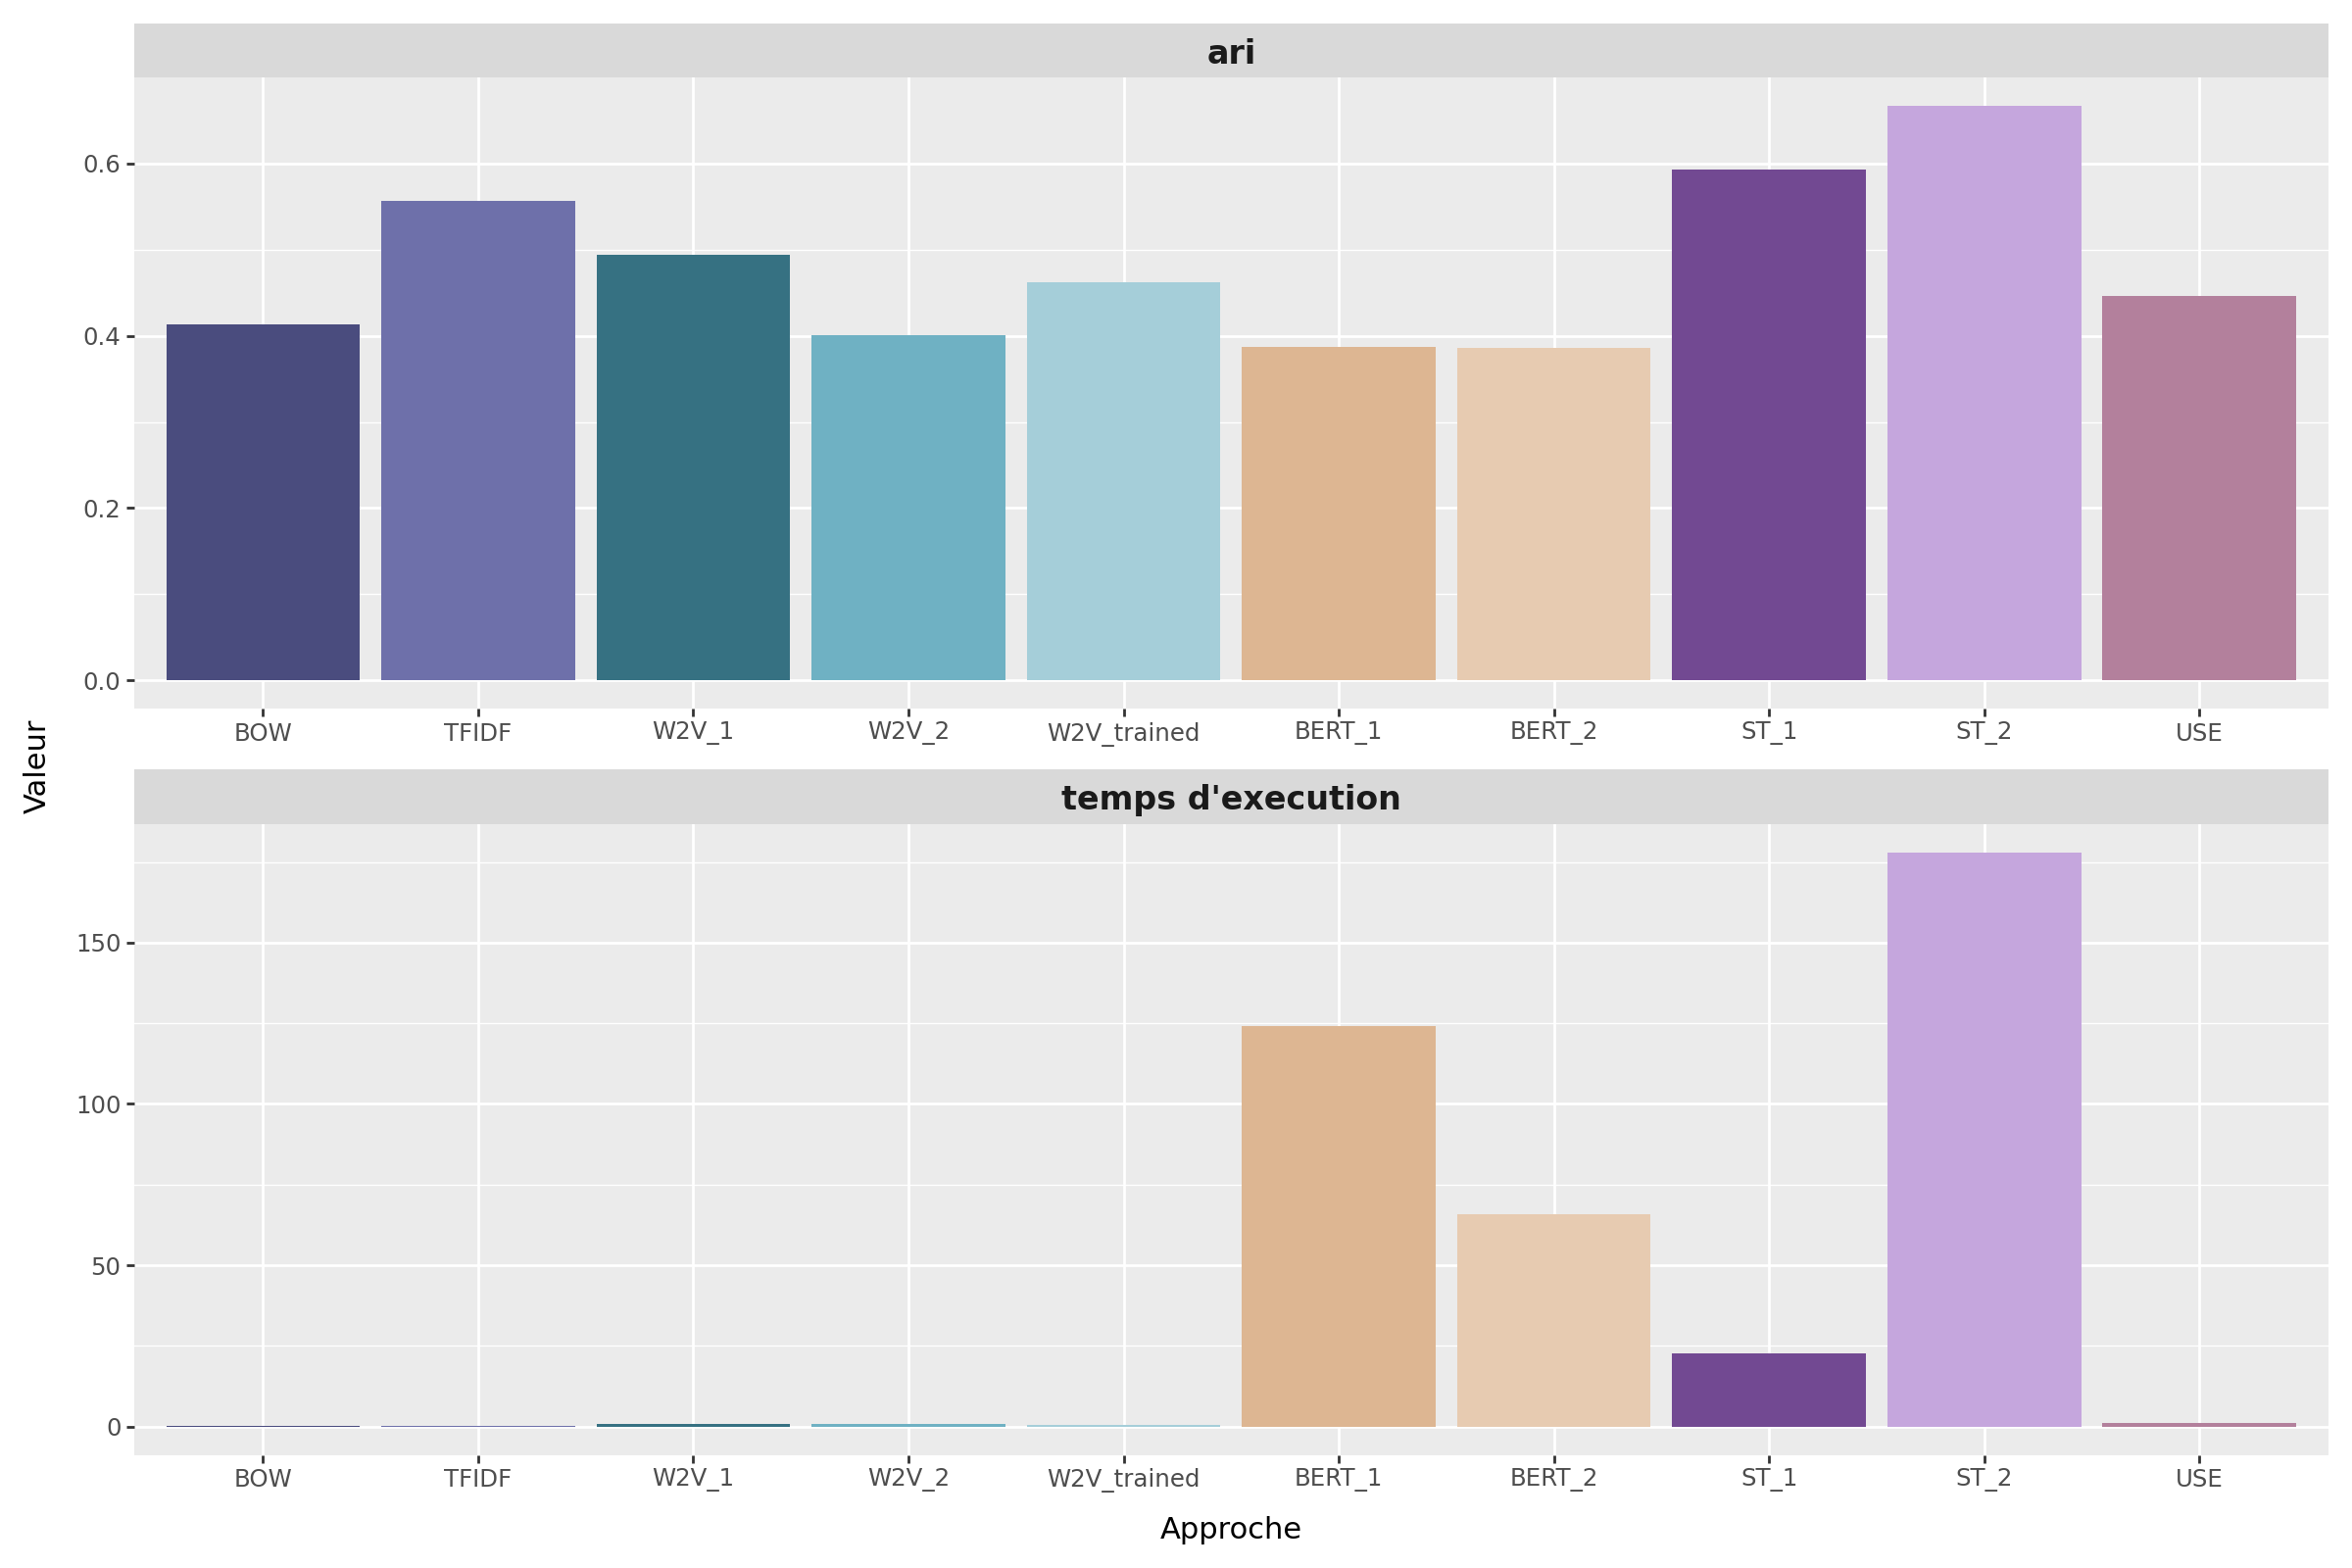

In [69]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="Saving .* in image\\.|Filename: .*",
)

# Reformatage de la table
resultats_pivot = pd.melt(
    Resultats,
    id_vars='approche',
    value_vars=['ari', "temps d'execution"],
    var_name='Score',
    value_name='Value'
)

# Détermination de l'ordre d'apparition des approches
ordre = ['BOW', 'TFIDF', 'W2V_1', 'W2V_2', 'W2V_trained', 'BERT_1','BERT_2', 'ST_1', 'ST_2', 'USE']

# Conversion de la variable approche en variable catégorielle
resultats_pivot['approche'] = pd.Categorical(resultats_pivot['approche'], categories=ordre, ordered=True)

# Définition d'un dictionnaire de correspondance de couleur
custom_colors = {
    'BOW': '#4a4c7e',  
    'TFIDF': '#6e70aa',  
    'W2V_1': '#367182',  
    'W2V_2': '#6fb1c3',
    'W2V_trained': '#a5ced9',
    'BERT_1': '#ddb692',
    'BERT_2': '#e7cbb1',
    'ST_1': '#724992',
    'ST_2': '#c5a6dd',
    'USE': '#b3809c'}

# Construction du graphique
p = (
    ggplot(resultats_pivot, aes(x='approche', y='Value', fill='approche')) +
    geom_bar(stat='identity', position='dodge') +
    facet_wrap('~Score', ncol=1, scales='free') +
    scale_fill_manual(values=custom_colors) +
    theme(
        figure_size=(12, 8),
        strip_text=element_text(size=12, weight='bold'),
        legend_position='none'
    ) +
    labs(
        y='Valeur',
        x='Approche'    )
)

# Sauvegarde du graphique
p.save(f"../Output/Extraction_de_features_texte/Comparaison_méthodes_d'extraction.png", dpi=300)


# Affichage du graphique
p


In [70]:
# Affichage des résultats
Resultats

,approche,ari,temps d'execution
0,BOW,0.413752,0.050908
0,TFIDF,0.557007,0.036914
0,W2V_1,0.494498,0.776038
0,W2V_2,0.400349,0.853211
0,W2V_trained,0.462717,0.461942
0,BERT_1,0.386927,124.293000
0,BERT_2,0.385994,65.771008
0,ST_1,0.593452,22.708428
0,ST_2,0.666591,177.944405
0,USE,0.445855,1.160239


Les différentes approches ont aboutis à des résultats comparables. Néanmoins, le deuxieme modèle de SentenceTransformer est l'approche qui a permis d'obtenir le meilleur score ARI. C'est cependant l'approche qui est également la plus couteuse en terme de temps de calcul. Les méthodes TF-IDF et BoW, bien que plus simples, offrent des résultats acceptables très rapidement, ce qui les rend intéressantes pour des situations où la rapidité est à priviligier. Les modèles de USE et de Word2Vec pré-entraînés représentent un bon compromis entre vitesse et performance. Concernant les modèles BERT on remarque qu'ils présentent ici les moins scores ARI ce qui est surprenant compte tenu de leur puissance théorique. Ces modèles pourraient éventuellement être optimisés mais les autres approches apportant de meilleurs résultats, on ne le fera pas ici.

# Conclusions

L'objectif de cette partie était d'étudier la faisabilité d'une classification de produits de la plateforme place de marché à partir des descriptions fournies par les vendeurs. Cette étude s'est décomposée en plusieurs étapes. Tout d'abord les descriptions ont été prétraitées via une séquence de différentes transformations et filtres incluant: la conversion en caractères minusculs, la tokenisation des descriptions, la suppression des stopwords,  la suppresion des caractères non alphabétiques, le filtre des mots trop fréquents ou trop rares, et enfin une étape de lémentisation ou de stematisaion.

L'étape suivante à consister à extraire des caractéristiques de ces descriptions prétraitées pour obtenir des vecteurs numériques. Là encore différentes approches ont été employées : (1) des méthodes simples comme BoW et TFIDF permettant de construire des vecteurs reflétant la fréquence des mots de l'ensemble du corpus pour chaque description (2) des approches basées sur des modèles pré entrainés. Pour chacune des approches les caractéristiques des différents produits ont été réduites grâce à un T-SNE puis projetées sur un espace bidimensionnel pour étudier la répartition des produits en fonction de leur catégories.

Les différentes approches ont conduit à des résultats globalement comparables, avec des scores d’ARI allant d’environ 0.38 pour les méthodes les moins performantes à 0.67 pour les meilleures. La majorité des scores se situent dans un interval intermédiaire entre 0.4 et 0.5, indiquant une certaine stabilité des performances quel que soit le type d’approche utilisé. Le modèle le plus performants correspondant a une méthode de Sentence Transformers est également celle dont le cout computationnel est le plus élevé. D'autres modèles comme ceux issus des approches W2V, tout comme le second modèle de Sentence transformer testés ici permettent d'atteindre des performances très correct en un temps nettement plus court. Il est également important de noter que les performances obtenues avec l’approche TF-IDF sont comparables à celles de ces méthodes plus avancées. Cette première phase exploratoire, au cours de laquelle les paramètres n'ont pas été optimisés, met en évidence le potentiel de ces méthodes pour la phase de classification automatique des produits à partir des descriptions.